In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *
from functions.repeated_cv import *
from functions.postproc import *
from functions.threshold import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis
from sksurv.linear_model import CoxnetSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data_cox/data.csv")

diagnosis_variables = []

with open("../../data/data_cox/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/data_cox/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

continuous_features =  ['Age', 'Ki67 positive cells (%) at CB',
                        'Conventional RT fraction', 'Total administered dose', 'Boost dose administered']

continuous_features = [col for col in continuous_features if col in feature_columns]

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
groups = survival_dataset['PERSON_ID']

# Stratification settings (toggle this flag)
n_splits = 5
use_time_strata = False  # Set to False to use outcome-only stratification
max_time_bins = 3

event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

strata_labels = None
chosen_bins = None
recurrence_mask = (event_col == 1)

if use_time_strata:
    # Outcome-Length stratification: time bins only for recurrence cases
    for n_bins in range(max_time_bins, 1, -1):
        try:
            # Build quantile bins using only recurrence cases
            recurrence_time_bins = pd.qcut(
                time_col.loc[recurrence_mask], q=n_bins, labels=False, duplicates='drop'
            )

            # Non-recurrence rows share one label; recurrence rows get time-bin labels
            candidate_labels = pd.Series('0_noevent', index=survival_dataset.index, dtype='object')
            candidate_labels.loc[recurrence_mask] = (
                '1_' + recurrence_time_bins.astype(int).astype(str)
            ).values

            # Every stratum must have at least n_splits samples for stable balancing
            if candidate_labels.value_counts().min() >= n_splits:
                strata_labels = candidate_labels
                chosen_bins = int(recurrence_time_bins.nunique())
                break
        except ValueError:
            continue

if strata_labels is None:
    # Explicit switch OR sparse recurrence-time bins -> outcome-only stratification
    strata_labels = event_col.astype(str)
    if use_time_strata:
        print('Fallback: using outcome-only stratification (recurrence time bins too sparse).')
    else:
        print('Using outcome-only stratification (time-based stratification disabled).')
else:
    print(f'Using recurrence-only time stratification with {chosen_bins} time bins.')

# sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
# cv = sgkf.split(X=data_x, y=strata_labels)

# train_index, test_index = next(cv)

manual_splits, manual_fold_summary = build_manual_stratified_group_folds(
    event_series=event_col,
    group_series=groups,
    strata_series=strata_labels,
    keep_groups_for_events=False,
    n_splits=n_splits,
    random_state=407
)

print('Manual grouped fold balancing summary:')
print(manual_fold_summary.to_string(index=False))

# Keep variable name for compatibility in later cells
cv = manual_splits
train_index, test_index = manual_splits[0]

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')

Using outcome-only stratification (time-based stratification disabled).
Manual grouped fold balancing summary:
 fold  target_events  assigned_events  target_samples  assigned_samples  valid_event_rate  target_event_strata_1  assigned_event_strata_1
    1              6                6             646               646          0.009288                      6                        6
    2              6                6             646               646          0.009288                      6                        6
    3              5                5             646               646          0.007740                      5                        5
    4              5                5             645               645          0.007752                      5                        5
    5              5                5             645               645          0.007752                      5                        5
Train size: 2582, Test size: 646


In [4]:
# Use the best model parameters found earlier
best_params_for_calibration = {
    'alphas': [0.000853168],
    'l1_ratio': 1.0,
    'fit_baseline_model': True
    }

n_controls = ["Full"]

In [5]:
from sklearn.preprocessing import MinMaxScaler

# Scale the training data using MinMaxScaler

scaler = MinMaxScaler()
x_train_scaled = x_train.copy()

cols_to_scale = [col for col in continuous_features if col in x_train_scaled.columns]
x_train_scaled[cols_to_scale] = scaler.fit_transform(x_train_scaled[cols_to_scale])

x_test_scaled = x_test.copy()
x_test_scaled[cols_to_scale] = scaler.transform(x_test_scaled[cols_to_scale])

print("Training data scaled successfully")
print(f"Shape: {x_train_scaled.shape}")

Training data scaled successfully
Shape: (2582, 30)


In [6]:
# Compute thresholds dynamically for every day in the 5-year window (inclusive)
time_points = np.arange(1, 1826, dtype=float)
report_time_points = np.array([365, 730, 1000, 1095, 1460, 1825], dtype=float)

# Class-specific costs for high-threshold optimization
high_false_positive_cost = 1.0
high_true_negative_cost = 0.0
high_false_negative_cost = 66.7
high_true_positive_cost = 0.0

n_bootstrap = 50
low_percentile = 20  # percentile for low-risk cutoff from bootstrapped model outputs

# Base model used for threshold estimation
threshold_estimator = CoxnetSurvivalAnalysis(**best_params_for_calibration)

### K optimization

In [15]:
# Tune EB K by FULL re-fit (not post-hoc) so it matches the production pipeline
k_grid_refit = np.array([0.5, 1.0, 2.0, 3.0, 5.0, 10.0], dtype=float)

# Use denser evaluation horizons than only report_time_points (monthly-like every 30 days + key report days)
eval_time_points = np.unique(np.concatenate([np.arange(180, 1826, 30, dtype=float), report_time_points.astype(float)]))
eval_time_to_idx = {float(t): i for i, t in enumerate(time_points.astype(float))}

# Evaluate tuning objective on TRAIN split (not test split)
event_field_train = y_train.dtype.names[0]
time_field_train = y_train.dtype.names[1]
event_train_local = y_train[event_field_train].astype(bool)
time_train_local = y_train[time_field_train].astype(float)

def mean_high_cost_from_thresholds(threshold_df, risk_matrix_train, eval_times):
    costs = []
    for t in eval_times:
        t = float(t)
        j = eval_time_to_idx.get(t, None)
        if j is None:
            continue

        row = threshold_df.loc[threshold_df['time'] == t]
        if row.empty:
            continue

        t_high = float(row.iloc[0]['t_high'])

        known_mask = (time_train_local >= t) | (event_train_local & (time_train_local <= t))
        if known_mask.sum() == 0:
            continue

        y_true = (event_train_local[known_mask] & (time_train_local[known_mask] <= t)).astype(int)
        y_pred_high = (risk_matrix_train[known_mask, j] >= t_high).astype(int)

        tp = int(np.sum((y_pred_high == 1) & (y_true == 1)))
        fn = int(np.sum((y_pred_high == 0) & (y_true == 1)))
        fp = int(np.sum((y_pred_high == 1) & (y_true == 0)))
        tn = int(np.sum((y_pred_high == 0) & (y_true == 0)))

        cost = (
            fp * float(high_false_positive_cost)
            + fn * float(high_false_negative_cost)
            + tp * float(high_true_positive_cost)
            + tn * float(high_true_negative_cost)
        ) / float(known_mask.sum())
        costs.append(cost)

    return float(np.mean(costs)) if len(costs) > 0 else np.nan

# Keep estimator and all settings fixed; only K changes
rows_refit = []
n_k = int(len(k_grid_refit))
overall_start = time.perf_counter()

print(f'Starting K full re-fit tuning on TRAIN for {n_k} candidates...')
for idx, k_value in enumerate(k_grid_refit, start=1):
    iter_start = time.perf_counter()

    threshold_result_k = fit_dynamic_thresholds(
        estimator=threshold_estimator,
        x_train=x_train_scaled,
        y_train=y_train,
        time_points=time_points,
        n_bootstrap=n_bootstrap,
        low_percentile=low_percentile,
        low_threshold_method='bootstrap_percentile',
        intermediate_threshold_method='mean_risk',
        high_threshold_method='empirical_bayes',
        high_eb_shrink_k=float(k_value),
        curve_spline_postprocess='high',
        curve_spline_variant='restricted',
        curve_spline_quantiles=(0.05, 0.275, 0.5, 0.725, 0.95),
        high_false_positive_cost=high_false_positive_cost,
        high_false_negative_cost=high_false_negative_cost,
        high_true_positive_cost=high_true_positive_cost,
        high_true_negative_cost=high_true_negative_cost,
        stratified_bootstrap=True,
        max_time_bins_for_bootstrap_strata=3,
        prevalence_method='kaplan_meier',
        utility_weighting='ipcw',
        threshold_estimation_method='point',
        random_state=12,
        verbose=False,
    )

    thresholds_k = threshold_result_k.thresholds
    risk_train_k = _build_risk_matrix(threshold_result_k.fitted_model, x_train_scaled, time_points)
    mean_cost_k = mean_high_cost_from_thresholds(thresholds_k, risk_train_k, eval_time_points)

    rows_refit.append({
        'k': float(k_value),
        'mean_cost_eval_times': mean_cost_k,
        't_high_end': float(thresholds_k['t_high'].iloc[-1]),
        't_high_peak': float(np.max(thresholds_k['t_high'].to_numpy(dtype=float))),
    })

    iter_elapsed = time.perf_counter() - iter_start
    total_elapsed = time.perf_counter() - overall_start
    avg_per_iter = total_elapsed / float(idx)
    eta_seconds = avg_per_iter * float(n_k - idx)
    print(
        f'[K tuning] {idx}/{n_k} | k={k_value:g} | iter={iter_elapsed:.2f}s | '
        f'elapsed={total_elapsed:.2f}s | ETA={eta_seconds:.2f}s'
    )

k_refit_results = pd.DataFrame(rows_refit).sort_values('mean_cost_eval_times', ascending=True).reset_index(drop=True)
k_refit_results['drop_peak_to_end'] = k_refit_results['t_high_peak'] - k_refit_results['t_high_end']

best_k_refit = float(k_refit_results.iloc[0]['k'])
total_runtime = time.perf_counter() - overall_start

print(f'Completed K tuning in {total_runtime:.2f}s.')
print('EB K tuning by FULL re-fit on TRAIN (lower cost is better):')
display(k_refit_results)
print(f'Best K by full re-fit objective: {best_k_refit:g}')

# Optional tie-break rule when costs are numerically equal
tol = 1e-12
tied = k_refit_results[k_refit_results['mean_cost_eval_times'] <= (k_refit_results['mean_cost_eval_times'].min() + tol)]
if len(tied) > 1:
    tied_sorted = tied.sort_values(['drop_peak_to_end', 'k'], ascending=[True, True])
    best_k_tiebreak = float(tied_sorted.iloc[0]['k'])
    print(f'Tie-break suggestion (smallest tail drop, then smallest K): {best_k_tiebreak:g}')

Starting K full re-fit tuning on TRAIN for 6 candidates...
[K tuning] 1/6 | k=0.5 | iter=52.00s | elapsed=52.01s | ETA=260.03s
[K tuning] 2/6 | k=1 | iter=47.19s | elapsed=99.20s | ETA=198.40s
[K tuning] 3/6 | k=2 | iter=50.22s | elapsed=149.42s | ETA=149.42s
[K tuning] 4/6 | k=3 | iter=43.19s | elapsed=192.61s | ETA=96.30s
[K tuning] 5/6 | k=5 | iter=50.23s | elapsed=242.83s | ETA=48.57s
[K tuning] 6/6 | k=10 | iter=34.68s | elapsed=277.52s | ETA=0.00s
Completed K tuning in 277.52s.
EB K tuning by FULL re-fit on TRAIN (lower cost is better):


,k,mean_cost_eval_times,t_high_end,t_high_peak,drop_peak_to_end
0,0.5,0.205129,0.022191,0.038636,0.016445
1,1.0,0.255575,0.030122,0.037666,0.007545
2,2.0,0.306755,0.037984,0.037984,0.000000
3,3.0,0.320933,0.041868,0.041868,0.000000
4,5.0,0.346805,0.045698,0.045698,0.000000
5,10.0,0.367022,0.049106,0.049106,0.000000


Best K by full re-fit objective: 0.5


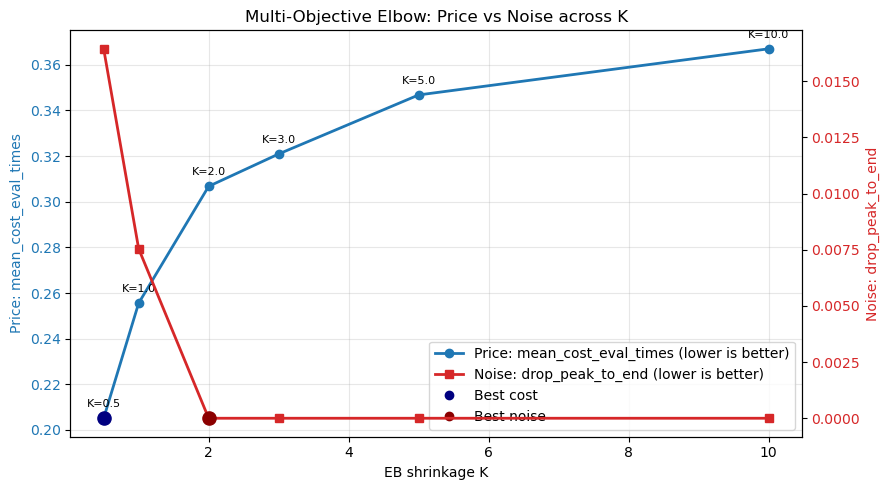

,k,mean_cost_eval_times,drop_peak_to_end
0,0.5,0.205129,0.016445
1,1.0,0.255575,0.007545
2,2.0,0.306755,0.000000
3,3.0,0.320933,0.000000
4,5.0,0.346805,0.000000
5,10.0,0.367022,0.000000


Interpretation tip: choose K near the elbow where cost is low and additional noise reduction starts to flatten.


In [16]:
# Multi-objective elbow plot for EB shrinkage K
required_cols = {'k', 'mean_cost_eval_times', 'drop_peak_to_end'}
if 'k_refit_results' not in globals():
    raise NameError("k_refit_results is not defined. Run the K full re-fit tuning cell first.")
if not required_cols.issubset(set(k_refit_results.columns)):
    raise ValueError(f"k_refit_results must contain columns: {sorted(required_cols)}")

elbow_df = (
    k_refit_results.loc[:, ['k', 'mean_cost_eval_times', 'drop_peak_to_end']]
    .dropna(subset=['k'])
    .sort_values('k')
    .reset_index(drop=True)
)

if elbow_df.empty:
    raise ValueError("No rows available in k_refit_results to plot.")

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

line1 = ax1.plot(
    elbow_df['k'],
    elbow_df['mean_cost_eval_times'],
    marker='o',
    linewidth=2,
    color='tab:blue',
    label='Price: mean_cost_eval_times (lower is better)'
)
line2 = ax2.plot(
    elbow_df['k'],
    elbow_df['drop_peak_to_end'],
    marker='s',
    linewidth=2,
    color='tab:red',
    label='Noise: drop_peak_to_end (lower is better)'
)

# Annotate each point with K for easier elbow reading
for _, r in elbow_df.iterrows():
    ax1.annotate(f"K={r['k']}", (r['k'], r['mean_cost_eval_times']), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)

ax1.set_xlabel('EB shrinkage K')
ax1.set_ylabel('Price: mean_cost_eval_times', color='tab:blue')
ax2.set_ylabel('Noise: drop_peak_to_end', color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax1.set_title('Multi-Objective Elbow: Price vs Noise across K')
ax1.grid(alpha=0.3)

# Optional: mark best-by-cost and best-by-noise
best_cost_idx = elbow_df['mean_cost_eval_times'].idxmin()
best_noise_idx = elbow_df['drop_peak_to_end'].idxmin()
ax1.scatter([elbow_df.loc[best_cost_idx, 'k']], [elbow_df.loc[best_cost_idx, 'mean_cost_eval_times']],
            color='navy', s=90, zorder=5, label='Best cost')
ax2.scatter([elbow_df.loc[best_noise_idx, 'k']], [elbow_df.loc[best_noise_idx, 'drop_peak_to_end']],
            color='darkred', s=90, zorder=5, label='Best noise')

# Combined legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
handles = lines + [
    plt.Line2D([0], [0], marker='o', color='navy', linestyle='None', label='Best cost'),
    plt.Line2D([0], [0], marker='o', color='darkred', linestyle='None', label='Best noise'),
]
labels += ['Best cost', 'Best noise']
ax1.legend(handles, labels, loc='best')

plt.tight_layout()
plt.show()

display(elbow_df)
print('Interpretation tip: choose K near the elbow where cost is low and additional noise reduction starts to flatten.')

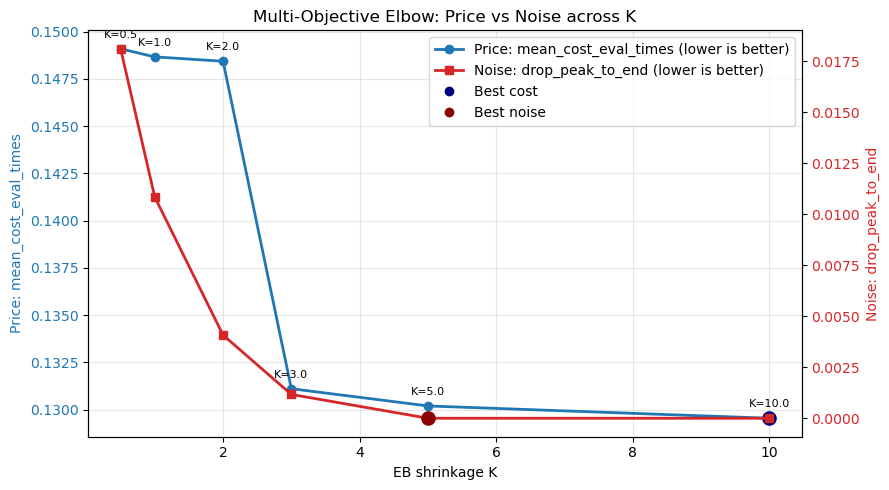

,k,mean_cost_eval_times,drop_peak_to_end
0,0.5,0.149086,0.018117
1,1.0,0.148660,0.010849
2,2.0,0.148428,0.004079
3,3.0,0.131114,0.001168
4,5.0,0.130202,0.000000
5,10.0,0.129552,0.000000


Interpretation tip: choose K near the elbow where cost is low and additional noise reduction starts to flatten.


In [ ]:
# Multi-objective elbow plot for EB shrinkage K
required_cols = {'k', 'mean_cost_eval_times', 'drop_peak_to_end'}
if 'k_refit_results' not in globals():
    raise NameError("k_refit_results is not defined. Run the K full re-fit tuning cell first.")
if not required_cols.issubset(set(k_refit_results.columns)):
    raise ValueError(f"k_refit_results must contain columns: {sorted(required_cols)}")

elbow_df = (
    k_refit_results.loc[:, ['k', 'mean_cost_eval_times', 'drop_peak_to_end']]
    .dropna(subset=['k'])
    .sort_values('k')
    .reset_index(drop=True)
)

if elbow_df.empty:
    raise ValueError("No rows available in k_refit_results to plot.")

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

line1 = ax1.plot(
    elbow_df['k'],
    elbow_df['mean_cost_eval_times'],
    marker='o',
    linewidth=2,
    color='tab:blue',
    label='Price: mean_cost_eval_times (lower is better)'
)
line2 = ax2.plot(
    elbow_df['k'],
    elbow_df['drop_peak_to_end'],
    marker='s',
    linewidth=2,
    color='tab:red',
    label='Noise: drop_peak_to_end (lower is better)'
)

# Annotate each point with K for easier elbow reading
for _, r in elbow_df.iterrows():
    ax1.annotate(f"K={r['k']}", (r['k'], r['mean_cost_eval_times']), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)

ax1.set_xlabel('EB shrinkage K')
ax1.set_ylabel('Price: mean_cost_eval_times', color='tab:blue')
ax2.set_ylabel('Noise: drop_peak_to_end', color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax1.set_title('Multi-Objective Elbow: Price vs Noise across K')
ax1.grid(alpha=0.3)

# Optional: mark best-by-cost and best-by-noise
best_cost_idx = elbow_df['mean_cost_eval_times'].idxmin()
best_noise_idx = elbow_df['drop_peak_to_end'].idxmin()
ax1.scatter([elbow_df.loc[best_cost_idx, 'k']], [elbow_df.loc[best_cost_idx, 'mean_cost_eval_times']],
            color='navy', s=90, zorder=5, label='Best cost')
ax2.scatter([elbow_df.loc[best_noise_idx, 'k']], [elbow_df.loc[best_noise_idx, 'drop_peak_to_end']],
            color='darkred', s=90, zorder=5, label='Best noise')

# Combined legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
handles = lines + [
    plt.Line2D([0], [0], marker='o', color='navy', linestyle='None', label='Best cost'),
    plt.Line2D([0], [0], marker='o', color='darkred', linestyle='None', label='Best noise'),
]
labels += ['Best cost', 'Best noise']
ax1.legend(handles, labels, loc='best')

plt.tight_layout()
plt.show()

display(elbow_df)
print('Interpretation tip: choose K near the elbow where cost is low and additional noise reduction starts to flatten.')

In [ ]:
# TEST set K tuning calculations only (no plotting)
if 'k_grid_refit' not in globals():
    k_grid_refit = np.array([0.5, 1.0, 2.0, 3.0, 5.0, 10.0], dtype=float)
if 'eval_time_points' not in globals():
    eval_time_points = np.unique(np.concatenate([np.arange(180, 1826, 30, dtype=float), report_time_points.astype(float)]))

eval_time_to_idx_test = {float(t): i for i, t in enumerate(time_points.astype(float))}

event_field_test = y_test.dtype.names[0]
time_field_test = y_test.dtype.names[1]
event_test_local = y_test[event_field_test].astype(bool)
time_test_local = y_test[time_field_test].astype(float)

def mean_high_cost_from_thresholds_test(threshold_df, risk_matrix_test, eval_times):
    costs = []
    for t in eval_times:
        t = float(t)
        j = eval_time_to_idx_test.get(t, None)
        if j is None:
            continue

        row = threshold_df.loc[threshold_df['time'] == t]
        if row.empty:
            continue

        t_high = float(row.iloc[0]['t_high'])
        known_mask = (time_test_local >= t) | (event_test_local & (time_test_local <= t))
        if known_mask.sum() == 0:
            continue

        y_true = (event_test_local[known_mask] & (time_test_local[known_mask] <= t)).astype(int)
        y_pred_high = (risk_matrix_test[known_mask, j] >= t_high).astype(int)

        tp = int(np.sum((y_pred_high == 1) & (y_true == 1)))
        fn = int(np.sum((y_pred_high == 0) & (y_true == 1)))
        fp = int(np.sum((y_pred_high == 1) & (y_true == 0)))
        tn = int(np.sum((y_pred_high == 0) & (y_true == 0)))

        cost = (
            fp * float(high_false_positive_cost)
            + fn * float(high_false_negative_cost)
            + tp * float(high_true_positive_cost)
            + tn * float(high_true_negative_cost)
        ) / float(known_mask.sum())
        costs.append(cost)

    return float(np.mean(costs)) if len(costs) > 0 else np.nan

rows_refit_test = []
n_k_test = int(len(k_grid_refit))
overall_start_test = time.perf_counter()

print(f'Starting K full re-fit tuning on TEST for {n_k_test} candidates...')
for idx, k_value in enumerate(k_grid_refit, start=1):
    iter_start = time.perf_counter()

    threshold_result_k = fit_dynamic_thresholds(
        estimator=threshold_estimator,
        x_train=x_train_scaled,
        y_train=y_train,
        time_points=time_points,
        n_bootstrap=n_bootstrap,
        low_percentile=low_percentile,
        low_threshold_method='bootstrap_percentile',
        intermediate_threshold_method='mean_risk',
        high_threshold_method='empirical_bayes',
        high_eb_shrink_k=float(k_value),
        curve_spline_postprocess='high',
        curve_spline_variant='restricted',
        curve_spline_quantiles=(0.05, 0.275, 0.5, 0.725, 0.95),
        high_false_positive_cost=high_false_positive_cost,
        high_false_negative_cost=high_false_negative_cost,
        high_true_positive_cost=high_true_positive_cost,
        high_true_negative_cost=high_true_negative_cost,
        stratified_bootstrap=True,
        max_time_bins_for_bootstrap_strata=3,
        prevalence_method='kaplan_meier',
        utility_weighting='ipcw',
        threshold_estimation_method='point',
        random_state=12,
        verbose=False,
    )

    thresholds_k = threshold_result_k.thresholds
    risk_test_k = _build_risk_matrix(threshold_result_k.fitted_model, x_test_scaled, time_points)
    mean_cost_k = mean_high_cost_from_thresholds_test(thresholds_k, risk_test_k, eval_time_points)

    rows_refit_test.append({
        'k': float(k_value),
        'mean_cost_eval_times': mean_cost_k,
        't_high_end': float(thresholds_k['t_high'].iloc[-1]),
        't_high_peak': float(np.max(thresholds_k['t_high'].to_numpy(dtype=float))),
    })

    iter_elapsed = time.perf_counter() - iter_start
    total_elapsed = time.perf_counter() - overall_start_test
    avg_per_iter = total_elapsed / float(idx)
    eta_seconds = avg_per_iter * float(n_k_test - idx)
    print(
        f'[K tuning TEST] {idx}/{n_k_test} | k={k_value:g} | iter={iter_elapsed:.2f}s | '
        f'elapsed={total_elapsed:.2f}s | ETA={eta_seconds:.2f}s'
    )

k_refit_results_test = pd.DataFrame(rows_refit_test).sort_values('mean_cost_eval_times', ascending=True).reset_index(drop=True)
k_refit_results_test['drop_peak_to_end'] = k_refit_results_test['t_high_peak'] - k_refit_results_test['t_high_end']

best_k_refit_test = float(k_refit_results_test.iloc[0]['k'])
total_runtime_test = time.perf_counter() - overall_start_test

print(f'Completed TEST K tuning in {total_runtime_test:.2f}s.')
print('EB K tuning by FULL re-fit on TEST (lower cost is better):')
display(k_refit_results_test)
print(f'Best K by full re-fit objective on TEST: {best_k_refit_test:g}')

Starting K full re-fit tuning on TEST for 6 candidates...
[K tuning TEST] 1/6 | k=0.5 | iter=22.62s | elapsed=22.62s | ETA=113.10s
[K tuning TEST] 2/6 | k=1 | iter=18.49s | elapsed=41.11s | ETA=82.21s
[K tuning TEST] 3/6 | k=2 | iter=18.62s | elapsed=59.73s | ETA=59.73s
[K tuning TEST] 4/6 | k=3 | iter=18.79s | elapsed=78.52s | ETA=39.26s
[K tuning TEST] 5/6 | k=5 | iter=21.58s | elapsed=100.10s | ETA=20.02s
[K tuning TEST] 6/6 | k=10 | iter=21.90s | elapsed=122.00s | ETA=0.00s
Completed TEST K tuning in 122.01s.
EB K tuning by FULL re-fit on TEST (lower cost is better):


,k,mean_cost_eval_times,t_high_end,t_high_peak,drop_peak_to_end
0,0.5,0.207004,0.032255,0.050372,0.018117
1,3.0,0.214121,0.052458,0.053626,0.001168
2,1.0,0.224433,0.040325,0.051175,0.010849
3,5.0,0.224897,0.056522,0.056522,0.000000
4,10.0,0.227093,0.060244,0.060244,0.000000
5,2.0,0.229713,0.048407,0.052486,0.004079


Best K by full re-fit objective on TEST: 0.5


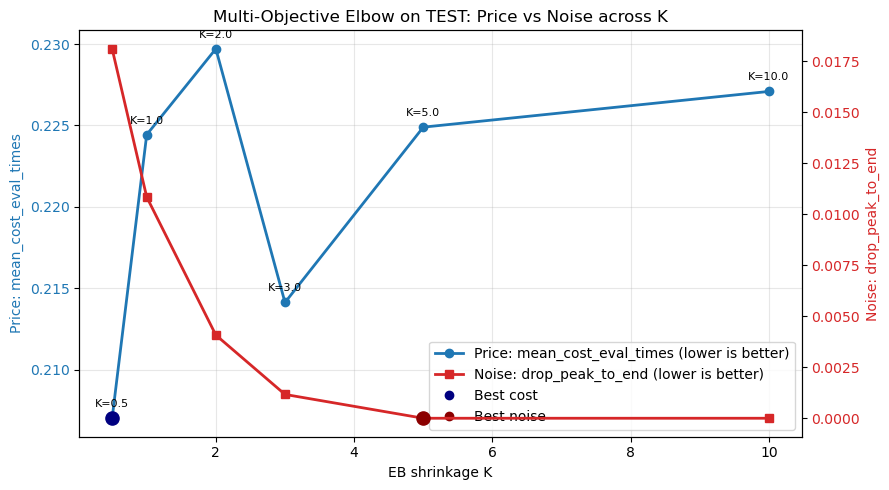

,k,mean_cost_eval_times,drop_peak_to_end
0,0.5,0.207004,0.018117
1,1.0,0.224433,0.010849
2,2.0,0.229713,0.004079
3,3.0,0.214121,0.001168
4,5.0,0.224897,0.000000
5,10.0,0.227093,0.000000


Interpretation tip: compare this TEST elbow with the TRAIN elbow in Cell 8.


In [ ]:
# Multi-objective elbow plot on TEST set (plotting only)
required_cols_test = {'k', 'mean_cost_eval_times', 'drop_peak_to_end'}
if 'k_refit_results_test' not in globals():
    raise NameError('k_refit_results_test is not defined. Run the previous TEST tuning cell first.')
if not required_cols_test.issubset(set(k_refit_results_test.columns)):
    raise ValueError(f"k_refit_results_test must contain columns: {sorted(required_cols_test)}")

elbow_df_test = (
    k_refit_results_test.loc[:, ['k', 'mean_cost_eval_times', 'drop_peak_to_end']]
    .dropna(subset=['k'])
    .sort_values('k')
    .reset_index(drop=True)
)

if elbow_df_test.empty:
    raise ValueError('No rows available in k_refit_results_test to plot.')

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

line1 = ax1.plot(
    elbow_df_test['k'],
    elbow_df_test['mean_cost_eval_times'],
    marker='o',
    linewidth=2,
    color='tab:blue',
    label='Price: mean_cost_eval_times (lower is better)'
)
line2 = ax2.plot(
    elbow_df_test['k'],
    elbow_df_test['drop_peak_to_end'],
    marker='s',
    linewidth=2,
    color='tab:red',
    label='Noise: drop_peak_to_end (lower is better)'
)

for _, r in elbow_df_test.iterrows():
    ax1.annotate(f"K={r['k']}", (r['k'], r['mean_cost_eval_times']), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)

ax1.set_xlabel('EB shrinkage K')
ax1.set_ylabel('Price: mean_cost_eval_times', color='tab:blue')
ax2.set_ylabel('Noise: drop_peak_to_end', color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax1.set_title('Multi-Objective Elbow on TEST: Price vs Noise across K')
ax1.grid(alpha=0.3)

best_cost_idx_test = elbow_df_test['mean_cost_eval_times'].idxmin()
best_noise_idx_test = elbow_df_test['drop_peak_to_end'].idxmin()
ax1.scatter([elbow_df_test.loc[best_cost_idx_test, 'k']], [elbow_df_test.loc[best_cost_idx_test, 'mean_cost_eval_times']],
            color='navy', s=90, zorder=5, label='Best cost')
ax2.scatter([elbow_df_test.loc[best_noise_idx_test, 'k']], [elbow_df_test.loc[best_noise_idx_test, 'drop_peak_to_end']],
            color='darkred', s=90, zorder=5, label='Best noise')

lines = line1 + line2
labels = [l.get_label() for l in lines]
handles = lines + [
    plt.Line2D([0], [0], marker='o', color='navy', linestyle='None', label='Best cost'),
    plt.Line2D([0], [0], marker='o', color='darkred', linestyle='None', label='Best noise'),
]
labels += ['Best cost', 'Best noise']
ax1.legend(handles, labels, loc='best')

plt.tight_layout()
plt.show()

display(elbow_df_test)
print('Interpretation tip: compare this TEST elbow with the TRAIN elbow in Cell 8.')

### Continuing

In [7]:
threshold_result = fit_dynamic_thresholds(
    estimator=threshold_estimator,
    x_train=x_train_scaled,
    y_train=y_train,
    time_points=time_points,
    n_bootstrap=n_bootstrap,
    low_percentile=low_percentile,
    low_threshold_method='bootstrap_percentile',
    intermediate_threshold_method="mean_risk",
    high_threshold_method='empirical_bayes',
    curve_spline_postprocess="all",
	curve_spline_variant="restricted",
	curve_spline_quantiles= (0.05, 0.275, 0.5, 0.725, 0.95), #(0.025, 0.1833, 0.3417, 0.5, 0.6583, 0.8167, 0.975), 
	# Place the knots using only the recurrences inside the 5-year horizon. With the
	# capping in cell 2 active this is a no-op (27/27 events), but it keeps knot
	# placement unchanged if the capping is ever switched off again.
	curve_spline_knots_within_grid=True,
	# Knot filter, NOT the day T_high leaves zero: knots land on [218, 602, 986,
	# 1266, 1757], and this drops the day-218 one because only 2 events have
	# accrued by then. Any cutoff in 219-602 gives the same curve; T_high then
	# leaves zero at ~day 192 as a consequence of the slope at the day-602 knot.
	high_curve_min_knot_time=450.0,
	# Pin the day T_high leaves zero. Without this it is whatever the straight-line
	# extrapolation below the day-602 knot gives (day 264); this swaps that line for
	# the quadratic that is zero on day 100 and joins the knot with the same value
	# and slope, so every horizon from day 602 on is unchanged.
	high_curve_zero_start_time=200.0,
    high_eb_shrink_k=3.0, # k=100 was tried here: it removes the zero start and adds a 5% tail roll-off
    high_false_positive_cost=high_false_positive_cost,
    high_false_negative_cost=high_false_negative_cost,
    high_true_positive_cost=high_true_positive_cost,
    high_true_negative_cost=high_true_negative_cost,
    stratified_bootstrap=True,
    max_time_bins_for_bootstrap_strata=3,   
    prevalence_method='kaplan_meier', #'empirical_known',
    utility_weighting='ipcw', #'unweighted',
    threshold_estimation_method="point",
    random_state=12,
    verbose=True,
    log_every_bootstrap=10
)


thresholds_df = threshold_result.thresholds
thresholds_report = thresholds_df[thresholds_df['time'].isin(report_time_points)][
    ['time', 't_low', 't_intermediate', 't_high', 'event_prevalence', 'roc_n_used', 'roc_computable']
]
train_risk_scores = threshold_result.risk_scores_train
fitted_threshold_model = threshold_result.fitted_model

display(thresholds_report)
print('Full dynamic threshold table (daily) is stored in thresholds_df.')

[fit_dynamic_thresholds] Starting threshold fitting...
[fit_dynamic_thresholds] n_samples=2582, n_time_points=1825
[fit_dynamic_thresholds] bootstrap enabled with n_bootstrap=50
[fit_dynamic_thresholds] low_threshold_method=bootstrap_percentile
[fit_dynamic_thresholds] intermediate_threshold_method=mean_risk
[fit_dynamic_thresholds] high_threshold_method=empirical_bayes
[fit_dynamic_thresholds] low_percentile=20.00


[fit_dynamic_thresholds] Base model fitted in 0.13s
[fit_dynamic_thresholds] global_event_prevalence=0.0134, global_m_low=73.6662, global_m_high=1.1044
[fit_dynamic_thresholds] prevalence_method=kaplan_meier
[fit_dynamic_thresholds] utility_weighting=ipcw
[fit_dynamic_thresholds] threshold_estimation_method=point
[fit_dynamic_thresholds] Built train risk matrix in 1.33s
[fit_dynamic_thresholds] t=183 bootstrap 10/50
[fit_dynamic_thresholds] t=183 bootstrap 20/50
[fit_dynamic_thresholds] t=183 bootstrap 30/50
[fit_dynamic_thresholds] t=183 bootstrap 40/50
[fit_dynamic_thresholds] t=183 bootstrap 50/50
[fit_dynamic_thresholds] t=365 bootstrap 10/50
[fit_dynamic_thresholds] t=365 bootstrap 20/50
[fit_dynamic_thresholds] t=365 bootstrap 30/50
[fit_dynamic_thresholds] t=365 bootstrap 40/50
[fit_dynamic_thresholds] t=365 bootstrap 50/50
[fit_dynamic_thresholds] t=547 bootstrap 10/50
[fit_dynamic_thresholds] t=547 bootstrap 20/50
[fit_dynamic_thresholds] t=547 bootstrap 30/50
[fit_dynamic_thr

,time,t_low,t_intermediate,t_high,event_prevalence,roc_n_used,roc_computable
364,365.0,0.000335,0.001520,0.005457,0.001183,2582,True
729,730.0,0.000646,0.002924,0.016853,0.002978,2582,True
999,1000.0,0.000994,0.004473,0.022597,0.004653,2582,True
1094,1095.0,0.001213,0.005437,0.023061,0.005256,2582,True
1459,1460.0,0.002216,0.009792,0.023186,0.008634,2582,True
1824,1825.0,0.002825,0.012371,0.029816,0.013393,2582,True


Full dynamic threshold table (daily) is stored in thresholds_df.


### False-negative cost sensitivity (5-year mark)

Sweep `high_false_negative_cost` and, for each value, refit the dynamic high threshold at the 5-year horizon (day 1825) using the exact same settings as the run above. For each cost, report — separately for the training cohort and the held-out test cohort:
- the resulting `t_high` at day 1825 (fit on train, applied to both),
- the % of the cohort flagged high-risk at day 1825,
- the % of all recurrences caught (i.e., flagged high-risk) at day 1825.

In [8]:
'''from functions.threshold import _extract_event_indicator, _build_risk_matrix

# NOTE: the loop below now honours fn_cost; previously it silently refit with the
# global high_false_negative_cost, making any sweep with >1 value a no-op.
fn_cost_values = [66.7]
horizon_time_point = 1825.0

event_mask_train = _extract_event_indicator(y_train)
n_recurrences_train = int(event_mask_train.sum())

event_mask_test = _extract_event_indicator(y_test)
n_recurrences_test = int(event_mask_test.sum())

fn_cost_sweep_rows = []
for fn_cost in fn_cost_values:
    sweep_result = fit_dynamic_thresholds(
        estimator=threshold_estimator,
        x_train=x_train_scaled,
        y_train=y_train,
        time_points=time_points,
        n_bootstrap=n_bootstrap,
        low_percentile=low_percentile,
        low_threshold_method='bootstrap_percentile',
        intermediate_threshold_method="mean_risk",
        high_threshold_method='empirical_bayes',
        curve_spline_postprocess="all",
        curve_spline_variant="restricted",
        curve_spline_quantiles= (0.05, 0.275, 0.5, 0.725, 0.95), #(0.025, 0.1833, 0.3417, 0.5, 0.6583, 0.8167, 0.975), 
        # Place the knots using only the recurrences inside the 5-year horizon. With the
        # capping in cell 2 active this is a no-op (27/27 events), but it keeps knot
        # placement unchanged if the capping is ever switched off again.
        curve_spline_knots_within_grid=True,
        # Knot filter, NOT the day T_high leaves zero: knots land on [218, 602, 986,
        # 1266, 1757], and this drops the day-218 one because only 2 events have
        # accrued by then. Any cutoff in 219-602 gives the same curve; T_high then
        # leaves zero at ~day 192 as a consequence of the slope at the day-602 knot.
        high_curve_min_knot_time=450.0,
        # Pin the day T_high leaves zero. Without this it is whatever the straight-line
        # extrapolation below the day-602 knot gives (day 264); this swaps that line for
        # the quadratic that is zero on day 100 and joins the knot with the same value
        # and slope, so every horizon from day 602 on is unchanged.
        high_curve_zero_start_time=150.0,
        high_eb_shrink_k=2.0, # k=100 was tried here: it removes the zero start and adds a 5% tail roll-off
        high_false_positive_cost=high_false_positive_cost,
        high_false_negative_cost=fn_cost,
        high_true_positive_cost=high_true_positive_cost,
        high_true_negative_cost=high_true_negative_cost,
        stratified_bootstrap=True,
        max_time_bins_for_bootstrap_strata=3,   
        prevalence_method='kaplan_meier', #'empirical_known',
        utility_weighting='ipcw', #'unweighted',
        threshold_estimation_method="point",
        random_state=12,
        verbose=True,
        log_every_bootstrap=10
    )

    t_high_at_horizon = float(
        sweep_result.thresholds.loc[
            sweep_result.thresholds['time'] == horizon_time_point, 't_high'
        ].iloc[0]
    )

    # Train cohort: risk scores already computed inside fit_dynamic_thresholds.
    risk_train_at_horizon = sweep_result.risk_scores_train[
        f'risk_t_{int(horizon_time_point)}'
    ].to_numpy()
    flagged_mask_train = risk_train_at_horizon >= t_high_at_horizon

    # Test cohort: score with the same fitted model, using the train-derived threshold.
    risk_test_at_horizon = _build_risk_matrix(
        sweep_result.fitted_model, x_test_scaled, [horizon_time_point]
    )[:, 0]
    flagged_mask_test = risk_test_at_horizon >= t_high_at_horizon

    n_flagged_train = int(flagged_mask_train.sum())
    n_caught_train = int((flagged_mask_train & event_mask_train).sum())

    n_flagged_test = int(flagged_mask_test.sum())
    n_caught_test = int((flagged_mask_test & event_mask_test).sum())

    fn_cost_sweep_rows.append({
        'high_false_negative_cost': fn_cost,
        't_high_at_1825d': t_high_at_horizon,
        'pct_cohort_flagged_train': 100.0 * n_flagged_train / len(flagged_mask_train),
        'pct_recurrences_caught_train': 100.0 * n_caught_train / n_recurrences_train,
        'n_flagged_train': n_flagged_train,
        'n_recurrences_caught_train': n_caught_train,
        'n_recurrences_total_train': n_recurrences_train,
        'pct_cohort_flagged_test': 100.0 * n_flagged_test / len(flagged_mask_test),
        'pct_recurrences_caught_test': 100.0 * n_caught_test / n_recurrences_test,
        'n_flagged_test': n_flagged_test,
        'n_recurrences_caught_test': n_caught_test,
        'n_recurrences_total_test': n_recurrences_test,
    })

    print(f"high_false_negative_cost={fn_cost} done: "
          f"t_high={t_high_at_horizon:.4f}, "
          f"train_flagged={n_flagged_train}/{len(flagged_mask_train)}, "
          f"train_caught={n_caught_train}/{n_recurrences_train}, "
          f"test_flagged={n_flagged_test}/{len(flagged_mask_test)}, "
          f"test_caught={n_caught_test}/{n_recurrences_test}")

fn_cost_sweep_df = pd.DataFrame(fn_cost_sweep_rows)
display(fn_cost_sweep_df)'''

'from functions.threshold import _extract_event_indicator, _build_risk_matrix\n\n# NOTE: the loop below now honours fn_cost; previously it silently refit with the\n# global high_false_negative_cost, making any sweep with >1 value a no-op.\nfn_cost_values = [66.7]\nhorizon_time_point = 1825.0\n\nevent_mask_train = _extract_event_indicator(y_train)\nn_recurrences_train = int(event_mask_train.sum())\n\nevent_mask_test = _extract_event_indicator(y_test)\nn_recurrences_test = int(event_mask_test.sum())\n\nfn_cost_sweep_rows = []\nfor fn_cost in fn_cost_values:\n    sweep_result = fit_dynamic_thresholds(\n        estimator=threshold_estimator,\n        x_train=x_train_scaled,\n        y_train=y_train,\n        time_points=time_points,\n        n_bootstrap=n_bootstrap,\n        low_percentile=low_percentile,\n        low_threshold_method=\'bootstrap_percentile\',\n        intermediate_threshold_method="mean_risk",\n        high_threshold_method=\'empirical_bayes\',\n        curve_spline_postp

In [9]:
from functions.threshold import _build_risk_matrix

# Build dynamic risk scores for training data
train_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_train_scaled, time_points)

def assign_dynamic_4zone_groups(risk_matrix, threshold_df, time_points):
    """Assign 4 zones using 3 thresholds: t_low, t_intermediate, t_high."""
    time_points = list(time_points)
    labels = np.empty_like(risk_matrix, dtype=object)

    for j, t_value in enumerate(time_points):
        row = threshold_df.loc[threshold_df['time'] == float(t_value)]
        if row.empty:
            raise ValueError(f"Missing threshold row for time point {t_value}.")

        t_low = float(row.iloc[0]['t_low'])
        t_intermediate = float(row.iloc[0]['t_intermediate'])
        t_high = float(row.iloc[0]['t_high'])

        # Keep monotonic threshold order for robust zoning.
        t_low, t_intermediate, t_high = sorted([t_low, t_intermediate, t_high])
        col_scores = risk_matrix[:, j]

        labels[:, j] = np.where(
            col_scores < t_low,
            'zone_1_low',
            np.where(
                col_scores < t_intermediate,
                'zone_2_mid_low',
                np.where(col_scores < t_high, 'zone_3_mid_high', 'zone_4_high'),
            ),
        )

    columns = [f'risk_group_t_{int(t)}' for t in time_points]
    return pd.DataFrame(labels, columns=columns)

train_groups = assign_dynamic_4zone_groups(train_risk_matrix, thresholds_df, time_points)

# Extract event/time fields from Surv structured array
event_field = y_train.dtype.names[0]
time_field = y_train.dtype.names[1]
event_train = y_train[event_field].astype(bool)
time_train = y_train[time_field].astype(float)

def _safe_div(num, den):
    return float(num / den) if den > 0 else np.nan

def summarize_group_metrics_train(group_df, selected_times, event_vec, time_vec):
    rows = []
    risk_groups = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']

    for t in selected_times:
        # Known status at horizon t: event by t OR survived/censored at or after t
        known_mask = (time_vec >= float(t)) | (event_vec & (time_vec <= float(t)))
        if known_mask.sum() == 0:
            continue

        y_true = (event_vec[known_mask] & (time_vec[known_mask] <= float(t))).astype(int)
        col = f'risk_group_t_{int(t)}'
        labels_t = group_df.loc[known_mask, col].values

        total_events = int(np.sum(y_true == 1))
        total_nonevents = int(np.sum(y_true == 0))

        for grp in risk_groups:
            grp_mask = (labels_t == grp)
            n_group = int(np.sum(grp_mask))

            # Truth inside the group
            events_in_group = int(np.sum(y_true[grp_mask] == 1)) if n_group > 0 else 0
            nonevents_in_group = int(np.sum(y_true[grp_mask] == 0)) if n_group > 0 else 0

            # True confusion metrics from predictions (one-vs-rest for this group)
            y_pred = grp_mask.astype(int)
            tp = int(np.sum((y_pred == 1) & (y_true == 1)))
            fn = int(np.sum((y_pred == 0) & (y_true == 1)))
            fp = int(np.sum((y_pred == 1) & (y_true == 0)))
            tn = int(np.sum((y_pred == 0) & (y_true == 0)))

            sensitivity = _safe_div(tp, tp + fn)
            specificity = _safe_div(tn, tn + fp)

            rows.append({
                'dataset': 'train',
                'time': float(t),
                'risk_group': grp,
                'n_known_total': int(known_mask.sum()),
                'n_group': n_group,
                'events_in_group': events_in_group,
                'nonevents_in_group': nonevents_in_group,
                'event_rate_in_group': _safe_div(events_in_group, n_group),
                'group_share': _safe_div(n_group, int(known_mask.sum())),
                'event_capture': _safe_div(events_in_group, total_events),
                'nonevent_capture': _safe_div(nonevents_in_group, total_nonevents),
                'tp': tp,
                'fn': fn,
                'fp': fp,
                'tn': tn,
                'sensitivity_tpr': sensitivity,
                'specificity_tnr': specificity,
            })

    out = pd.DataFrame(rows)

    # Force all time x group combinations to be visible (including empty groups).
    zone_order = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']
    full_index = pd.MultiIndex.from_product(
        [selected_times.astype(float), zone_order],
        names=['time', 'risk_group'],
    )
    out = (
        out.set_index(['time', 'risk_group'])
           .reindex(full_index)
           .reset_index()
    )
    out['dataset'] = out['dataset'].fillna('train')
    out['n_group'] = out['n_group'].fillna(0).astype(int)
    out['events_in_group'] = out['events_in_group'].fillna(0).astype(int)
    out['nonevents_in_group'] = out['nonevents_in_group'].fillna(0).astype(int)

    # Keep a stable, intuitive zone order in display.
    out['risk_group'] = pd.Categorical(
        out['risk_group'],
        categories=zone_order,
        ordered=True,
    )
    return out

group_metrics_train = summarize_group_metrics_train(
    train_groups,
    report_time_points,
    event_train,
    time_train,
)

# Long-format metrics
display(group_metrics_train.sort_values(['time', 'risk_group']))

# Wide-format patient counts per zone: always show all 4 zones
zone_order = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']
zone_counts_train = (
    group_metrics_train
    .pivot(index='time', columns='risk_group', values='n_group')
    .reindex(columns=zone_order, fill_value=0)
    .rename_axis(columns=None)
    .reset_index()
)
print('Patients per zone (train, 4 zones):')
display(zone_counts_train)

,time,risk_group,dataset,n_known_total,n_group,events_in_group,nonevents_in_group,event_rate_in_group,group_share,event_capture,nonevent_capture,tp,fn,fp,tn,sensitivity_tpr,specificity_tnr
0,365.0,zone_1_low,train,2443,1115,0,1115,0.000000,0.456406,0.000000,0.456967,0,3,1115,1325,0.000000,0.543033
1,365.0,zone_2_mid_low,train,2443,804,0,804,0.000000,0.329104,0.000000,0.329508,0,3,804,1636,0.000000,0.670492
2,365.0,zone_3_mid_high,train,2443,450,1,449,0.002222,0.184200,0.333333,0.184016,1,2,449,1991,0.333333,0.815984
3,365.0,zone_4_high,train,2443,74,2,72,0.027027,0.030291,0.666667,0.029508,2,1,72,2368,0.666667,0.970492
4,730.0,zone_1_low,train,1910,86,0,86,0.000000,0.045026,0.000000,0.045192,0,7,86,1817,0.000000,0.954808
5,730.0,zone_2_mid_low,train,1910,1324,0,1324,0.000000,0.693194,0.000000,0.695744,0,7,1324,579,0.000000,0.304256
6,730.0,zone_3_mid_high,train,1910,453,2,451,0.004415,0.237173,0.285714,0.236994,2,5,451,1452,0.285714,0.763006
7,730.0,zone_4_high,train,1910,47,5,42,0.106383,0.024607,0.714286,0.022070,5,2,42,1861,0.714286,0.977930
8,1000.0,zone_1_low,train,1697,76,0,76,0.000000,0.044785,0.000000,0.045050,0,10,76,1611,0.000000,0.954950
9,1000.0,zone_2_mid_low,train,1697,1176,0,1176,0.000000,0.692988,0.000000,0.697095,0,10,1176,511,0.000000,0.302905


Patients per zone (train, 4 zones):


,time,zone_1_low,zone_2_mid_low,zone_3_mid_high,zone_4_high
0,365.0,1115,804,450,74
1,730.0,86,1324,453,47
2,1000.0,76,1176,393,52
3,1095.0,653,559,385,52
4,1460.0,519,358,229,85
5,1825.0,46,633,170,104


In [10]:
# Zone-level threshold + survival summary table (train)
from scipy.stats import norm


def _safe_pct_no_event(events_in_group, n_group):
    if n_group <= 0:
        return np.nan
    return float(100.0 * (1.0 - (events_in_group / n_group)))


def _align_group_time_event(group_df, event_vec, time_vec):
    """Guard against notebook state drift where arrays were rebuilt with different split sizes."""
    n_group = int(len(group_df))
    n_event = int(len(event_vec))
    n_time = int(len(time_vec))
    n = min(n_group, n_event, n_time)

    if (n_group != n) or (n_event != n) or (n_time != n):
        print(
            'Warning: length mismatch detected; aligning to minimum length. '
            f'group_df={n_group}, event_vec={n_event}, time_vec={n_time}, using n={n}.'
        )

    return group_df.iloc[:n].copy(), np.asarray(event_vec)[:n], np.asarray(time_vec)[:n]


def _incidence_rate_hr_fallback(observed_time, observed_event, group_labels, zone_order):
    """Fallback HR approximation using incidence rate ratio with continuity correction."""
    out = {
        z: {
            'hazard_ratio_vs_zone_1_low': np.nan,
            'hr_95ci_lower': np.nan,
            'hr_95ci_upper': np.nan,
            'hr_p_value': np.nan,
            'hr_method': 'fallback_ir',
        }
        for z in zone_order
    }

    ref = zone_order[0]
    labels = np.asarray(group_labels, dtype=object)
    time_arr = np.asarray(observed_time, dtype=float)
    event_arr = np.asarray(observed_event, dtype=int)

    ref_mask = labels == ref
    if np.sum(ref_mask) == 0:
        return out

    e_ref = float(np.sum(event_arr[ref_mask]))
    pt_ref = float(np.sum(np.clip(time_arr[ref_mask], 1e-8, None)))
    if pt_ref <= 0:
        return out

    out[ref] = {
        'hazard_ratio_vs_zone_1_low': 1.0,
        'hr_95ci_lower': np.nan,
        'hr_95ci_upper': np.nan,
        'hr_p_value': np.nan,
        'hr_method': 'reference',
    }

    for z in zone_order[1:]:
        z_mask = labels == z
        n_z = int(np.sum(z_mask))
        if n_z == 0:
            continue

        e_z = float(np.sum(event_arr[z_mask]))
        pt_z = float(np.sum(np.clip(time_arr[z_mask], 1e-8, None)))
        if pt_z <= 0:
            continue

        e_ref_cc = e_ref + 0.5
        e_z_cc = e_z + 0.5

        rate_ref = e_ref_cc / pt_ref
        rate_z = e_z_cc / pt_z
        if rate_ref <= 0 or rate_z <= 0:
            continue

        log_hr = float(np.log(rate_z / rate_ref))
        se = float(np.sqrt((1.0 / e_z_cc) + (1.0 / e_ref_cc)))
        if not np.isfinite(se) or se <= 0:
            continue

        z_score = log_hr / se
        pval = float(2.0 * (1.0 - norm.cdf(np.abs(z_score))))

        lower = float(np.exp(log_hr - 1.96 * se))
        upper = float(np.exp(log_hr + 1.96 * se))
        hr = float(np.exp(log_hr))

        out[z] = {
            'hazard_ratio_vs_zone_1_low': hr,
            'hr_95ci_lower': lower,
            'hr_95ci_upper': upper,
            'hr_p_value': pval,
            'hr_method': 'fallback_ir',
        }

    return out


def _fit_hr_with_ci(observed_time, observed_event, group_labels, zone_order):
    """Estimate HR vs zone_1_low with Cox PH; fallback to incidence-rate HR when unstable."""
    base = {
        z: {
            'hazard_ratio_vs_zone_1_low': np.nan,
            'hr_95ci_lower': np.nan,
            'hr_95ci_upper': np.nan,
            'hr_p_value': np.nan,
            'hr_method': 'missing',
        }
        for z in zone_order
    }
    base[zone_order[0]] = {
        'hazard_ratio_vs_zone_1_low': 1.0,
        'hr_95ci_lower': np.nan,
        'hr_95ci_upper': np.nan,
        'hr_p_value': np.nan,
        'hr_method': 'reference',
    }

    labels = np.asarray(group_labels, dtype=object)
    obs_event = np.asarray(observed_event, dtype=int)
    obs_time = np.asarray(observed_time, dtype=float)

    if len(np.unique(labels)) < 2 or np.sum(obs_event) == 0:
        return _incidence_rate_hr_fallback(obs_time, obs_event, labels, zone_order)

    try:
        from statsmodels.duration.hazard_regression import PHReg

        cat = pd.Categorical(labels, categories=zone_order, ordered=True)
        exog = pd.get_dummies(cat, drop_first=True).astype(float)

        if exog.shape[1] == 0:
            return _incidence_rate_hr_fallback(obs_time, obs_event, labels, zone_order)

        model = PHReg(
            endog=obs_time,
            exog=exog.to_numpy(dtype=float),
            status=obs_event,
            ties='efron',
        )
        result = model.fit(disp=0)

        params = np.asarray(result.params, dtype=float)
        bse = np.asarray(result.bse, dtype=float)

        for i, col in enumerate(exog.columns):
            zone_name = str(col)
            beta = float(params[i])
            se = float(bse[i])

            if not np.isfinite(beta) or not np.isfinite(se) or se <= 0:
                continue

            upper_log = beta + 1.96 * se
            lower_log = beta - 1.96 * se
            if (not np.isfinite(upper_log)) or (not np.isfinite(lower_log)) or (upper_log > 700) or (lower_log < -700):
                continue

            hr = float(np.exp(beta))
            lower = float(np.exp(lower_log))
            upper = float(np.exp(upper_log))
            z_score = beta / se
            pval = float(2.0 * (1.0 - norm.cdf(np.abs(z_score))))

            if not (np.isfinite(hr) and np.isfinite(lower) and np.isfinite(upper) and np.isfinite(pval)):
                continue

            base[zone_name] = {
                'hazard_ratio_vs_zone_1_low': hr,
                'hr_95ci_lower': lower,
                'hr_95ci_upper': upper,
                'hr_p_value': pval,
                'hr_method': 'coxph_wald',
            }

        missing_nonref = [
            z for z in zone_order[1:]
            if pd.isna(base[z]['hazard_ratio_vs_zone_1_low'])
        ]
        if missing_nonref:
            fb = _incidence_rate_hr_fallback(obs_time, obs_event, labels, zone_order)
            for z in missing_nonref:
                base[z] = fb.get(z, base[z])

        return base

    except Exception:
        return _incidence_rate_hr_fallback(obs_time, obs_event, labels, zone_order)


def build_zone_threshold_survival_table(group_df, selected_times, event_vec, time_vec, threshold_df, dataset_label):
    zone_order = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']
    rows = []

    group_df_aligned, event_aligned, time_aligned = _align_group_time_event(group_df, event_vec, time_vec)

    for t in selected_times.astype(float):
        known_mask = (time_aligned >= float(t)) | (event_aligned & (time_aligned <= float(t)))
        if known_mask.sum() == 0:
            continue

        col = f'risk_group_t_{int(t)}'
        labels_t = group_df_aligned.loc[known_mask, col].astype(str).to_numpy()

        observed_time = np.minimum(time_aligned[known_mask].astype(float), float(t))
        observed_event = (event_aligned[known_mask] & (time_aligned[known_mask] <= float(t))).astype(int)

        hr_map = _fit_hr_with_ci(observed_time, observed_event, labels_t, zone_order)

        thr_row = threshold_df.loc[threshold_df['time'] == float(t)]
        if thr_row.empty:
            t_low = np.nan
            t_intermediate = np.nan
            t_high = np.nan
        else:
            t_low = float(thr_row.iloc[0]['t_low'])
            t_intermediate = float(thr_row.iloc[0]['t_intermediate'])
            t_high = float(thr_row.iloc[0]['t_high'])

        for grp in zone_order:
            grp_mask = labels_t == grp
            n_group = int(np.sum(grp_mask))

            if n_group > 0:
                grp_event = observed_event[grp_mask]
                events_in_group = int(np.sum(grp_event))
                os_percent_no_event = _safe_pct_no_event(events_in_group, n_group)
            else:
                events_in_group = 0
                os_percent_no_event = np.nan

            hr_stats = hr_map.get(grp, {
                'hazard_ratio_vs_zone_1_low': np.nan,
                'hr_95ci_lower': np.nan,
                'hr_95ci_upper': np.nan,
                'hr_p_value': np.nan,
                'hr_method': 'missing',
            })

            rows.append({
                'dataset': dataset_label,
                'time': float(t),
                'risk_group': grp,
                'n_group': n_group,
                'events_in_group': events_in_group,
                'os_percent_no_event': os_percent_no_event,
                't_low': t_low,
                't_intermediate': t_intermediate,
                't_high': t_high,
                'hazard_ratio_vs_zone_1_low': hr_stats['hazard_ratio_vs_zone_1_low'],
                'hr_95ci_lower': hr_stats['hr_95ci_lower'],
                'hr_95ci_upper': hr_stats['hr_95ci_upper'],
                'hr_p_value': hr_stats['hr_p_value'],
                'hr_method': hr_stats['hr_method'],
            })

    out = pd.DataFrame(rows)
    if out.empty:
        return out

    out['risk_group'] = pd.Categorical(out['risk_group'], categories=zone_order, ordered=True)
    return out.sort_values(['time', 'risk_group']).reset_index(drop=True)


zone_threshold_survival_train = build_zone_threshold_survival_table(
    group_df=train_groups,
    selected_times=report_time_points,
    event_vec=event_train,
    time_vec=time_train,
    threshold_df=thresholds_df,
    dataset_label='train',
)

zone_threshold_survival_train['hazard_ratio_95ci'] = np.where(
    zone_threshold_survival_train['hazard_ratio_vs_zone_1_low'].notna(),
    zone_threshold_survival_train['hazard_ratio_vs_zone_1_low'].map(lambda x: f"{x:.3f}")
    + ' ['
    + zone_threshold_survival_train['hr_95ci_lower'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'NA')
    + ', '
    + zone_threshold_survival_train['hr_95ci_upper'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'NA')
    + ']',
    'NA',
)

print('Thresholds, OS% (no event), and hazard ratio (95% CI) per zone (train):')
display(
    zone_threshold_survival_train[
        [
            'time',
            'risk_group',
            'n_group',
            'events_in_group',
            'os_percent_no_event',
            't_low',
            't_intermediate',
            't_high',
            'hazard_ratio_95ci',
            'hr_p_value',
            'hr_method',
        ]
    ]
)

Thresholds, OS% (no event), and hazard ratio (95% CI) per zone (train):


,time,risk_group,n_group,events_in_group,os_percent_no_event,t_low,t_intermediate,t_high,hazard_ratio_95ci,hr_p_value,hr_method
0,365.0,zone_1_low,1115,0,100.000000,0.000335,0.001520,0.005457,"1.000 [NA, NA]",NaN,reference
1,365.0,zone_2_mid_low,804,0,100.000000,0.000335,0.001520,0.005457,"1.387 [0.028, 69.896]",0.870121,fallback_ir
2,365.0,zone_3_mid_high,450,1,99.777778,0.000335,0.001520,0.005457,"7.441 [0.303, 182.672]",0.219054,fallback_ir
3,365.0,zone_4_high,74,2,97.297297,0.000335,0.001520,0.005457,"76.213 [3.659, 1587.547]",0.005153,fallback_ir
4,730.0,zone_1_low,86,0,100.000000,0.000646,0.002924,0.016853,"1.000 [NA, NA]",NaN,reference
5,730.0,zone_2_mid_low,1324,0,100.000000,0.000646,0.002924,0.016853,"0.065 [0.001, 3.274]",0.171615,fallback_ir
6,730.0,zone_3_mid_high,453,2,99.558499,0.000646,0.002924,0.016853,"0.951 [0.046, 19.813]",0.974211,fallback_ir
7,730.0,zone_4_high,47,5,89.361702,0.000646,0.002924,0.016853,"21.263 [1.176, 384.553]",0.038492,fallback_ir
8,1000.0,zone_1_low,76,0,100.000000,0.000994,0.004473,0.022597,"1.000 [NA, NA]",NaN,reference
9,1000.0,zone_2_mid_low,1176,0,100.000000,0.000994,0.004473,0.022597,"0.065 [0.001, 3.257]",0.170821,fallback_ir


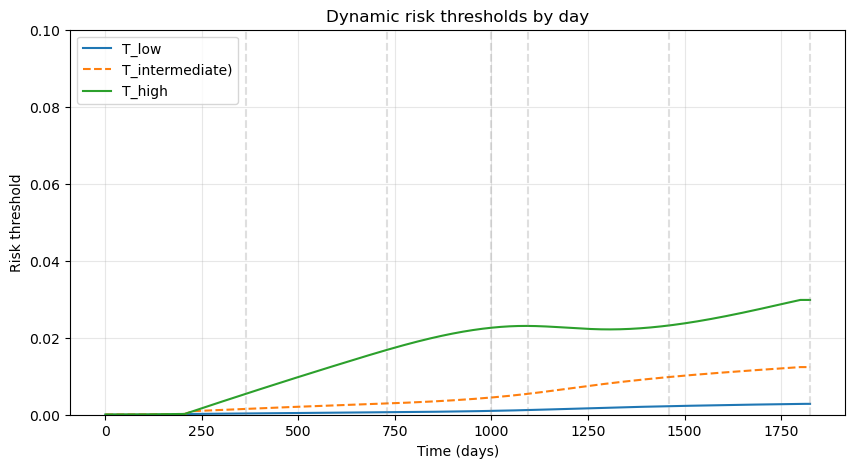

In [11]:
# Visual check: threshold evolution over time (daily)
plt.figure(figsize=(10, 5))
plt.plot(thresholds_df['time'], thresholds_df['t_low'], label='T_low')
plt.plot(
    thresholds_df['time'],
    thresholds_df['t_intermediate'],
    label=f"T_intermediate)",
    linestyle='--',
)
plt.plot(thresholds_df['time'], thresholds_df['t_high'], label='T_high')

# Highlight key horizons
for t in report_time_points:
    plt.axvline(t, color='gray', linestyle='--', alpha=0.25)

plt.xlabel('Time (days)')
plt.ylabel('Risk threshold')
plt.ylim(0.0, 0.1)
plt.title('Dynamic risk thresholds by day')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

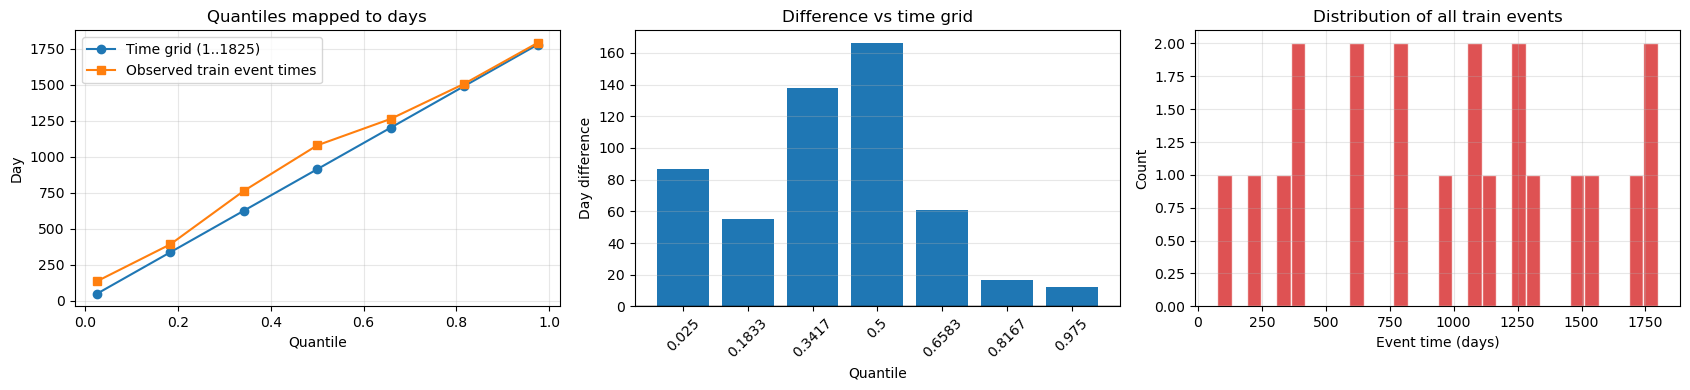

Quantile-day tables:


,quantile,day_on_time_grid,day_on_event_times_train
0,0.0250,46.6000,133.500
1,0.1833,335.3392,390.324
2,0.3417,624.2608,762.112
3,0.5000,913.0000,1079.000
4,0.6583,1201.7392,1262.830
5,0.8167,1490.6608,1507.036
6,0.9750,1779.4000,1791.500


Total number of observed events in train set: 21


In [12]:
# Quantiles used in fit_dynamic_thresholds
q = np.array([0.025, 0.1833, 0.3417, 0.5, 0.6583, 0.8167, 0.975], dtype=float)

# Day correspondence on the model time grid (1..1825)
quantile_days = pd.DataFrame({
    "quantile": q,
    "day_on_time_grid": np.quantile(time_points, q)
})

# Event-only quantiles from train outcomes
event_times_train = y_train["time"][y_train["event"]]
quantile_days_event_only = pd.DataFrame({
    "quantile": q,
    "day_on_event_times_train": np.quantile(event_times_train, q)
})

# Merge for side-by-side plotting
quantile_compare = quantile_days.merge(quantile_days_event_only, on="quantile")

# Graphical view
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

# Left: quantile -> day mapping
ax[0].plot(
    quantile_compare["quantile"],
    quantile_compare["day_on_time_grid"],
    marker="o",
    label="Time grid (1..1825)"
)
ax[0].plot(
    quantile_compare["quantile"],
    quantile_compare["day_on_event_times_train"],
    marker="s",
    label="Observed train event times"
)
ax[0].set_title("Quantiles mapped to days")
ax[0].set_xlabel("Quantile")
ax[0].set_ylabel("Day")
ax[0].grid(alpha=0.3)
ax[0].legend()

# Middle: difference (event-only - grid)
diff = quantile_compare["day_on_event_times_train"] - quantile_compare["day_on_time_grid"]
ax[1].bar(quantile_compare["quantile"].astype(str), diff)
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_title("Difference vs time grid")
ax[1].set_xlabel("Quantile")
ax[1].set_ylabel("Day difference")
ax[1].tick_params(axis="x", rotation=45)
ax[1].grid(axis="y", alpha=0.3)

# Right: all event times in train set
ax[2].hist(event_times_train, bins=30, alpha=0.8, color="tab:red", edgecolor="white")
ax[2].set_title("Distribution of all train events")
ax[2].set_xlabel("Event time (days)")
ax[2].set_ylabel("Count")
ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Quantile-day tables:")
display(quantile_compare)

print(f"Total number of observed events in train set: {event_times_train.shape[0]}")

In [13]:
# Test-set evaluation using training-derived dynamic thresholds
from sksurv.metrics import concordance_index_censored

# 1) Global discrimination on test set (C-index)
event_field_test = y_test.dtype.names[0]
time_field_test = y_test.dtype.names[1]
event_test = y_test[event_field_test].astype(bool)
time_test = y_test[time_field_test].astype(float)

# For Cox models, higher linear predictor means higher risk.
test_risk_score_global = fitted_threshold_model.predict(x_test_scaled)
c_index_test = concordance_index_censored(event_test, time_test, test_risk_score_global)[0]
print(f"Test Harrell C-index: {c_index_test:.4f}")

train_risk_score_global = fitted_threshold_model.predict(x_train_scaled)
c_index_train = concordance_index_censored(event_train, time_train, train_risk_score_global)[0]
print(f"Train Harrell C-index: {c_index_train:.4f}")

# 2) Dynamic risk groups on test set using thresholds learned from training (4 zones)
test_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_test_scaled, time_points)
test_groups = assign_dynamic_4zone_groups(test_risk_matrix, thresholds_df, time_points)

def _safe_div_test(num, den):
    return float(num / den) if den > 0 else np.nan

def summarize_group_metrics_test(group_df, selected_times, event_vec, time_vec):
    rows = []
    risk_groups = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']

    for t in selected_times:
        known_mask = (time_vec >= float(t)) | (event_vec & (time_vec <= float(t)))
        if known_mask.sum() == 0:
            continue

        y_true = (event_vec[known_mask] & (time_vec[known_mask] <= float(t))).astype(int)
        labels_t = group_df.loc[known_mask, f'risk_group_t_{int(t)}'].values

        total_events = int(np.sum(y_true == 1))
        total_nonevents = int(np.sum(y_true == 0))

        for grp in risk_groups:
            grp_mask = (labels_t == grp)
            n_group = int(np.sum(grp_mask))
            events_in_group = int(np.sum(y_true[grp_mask] == 1)) if n_group > 0 else 0
            nonevents_in_group = int(np.sum(y_true[grp_mask] == 0)) if n_group > 0 else 0

            rows.append({
                'dataset': 'test',
                'time': float(t),
                'risk_group': grp,
                'n_known_total': int(known_mask.sum()),
                'n_group': n_group,
                'events_in_group': events_in_group,
                'nonevents_in_group': nonevents_in_group,
                'event_rate_in_group': _safe_div_test(events_in_group, n_group),
                'group_share': _safe_div_test(n_group, int(known_mask.sum())),
                'event_capture': _safe_div_test(events_in_group, total_events),
                'nonevent_capture': _safe_div_test(nonevents_in_group, total_nonevents),
            })

    out = pd.DataFrame(rows)
    zone_order = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']
    full_index = pd.MultiIndex.from_product(
        [selected_times.astype(float), zone_order],
        names=['time', 'risk_group'],
    )
    out = out.set_index(['time', 'risk_group']).reindex(full_index).reset_index()
    out['dataset'] = out['dataset'].fillna('test')
    out['n_group'] = out['n_group'].fillna(0).astype(int)
    out['events_in_group'] = out['events_in_group'].fillna(0).astype(int)
    out['nonevents_in_group'] = out['nonevents_in_group'].fillna(0).astype(int)
    out['risk_group'] = pd.Categorical(
        out['risk_group'],
        categories=zone_order,
        ordered=True,
    )
    return out

group_metrics_test = summarize_group_metrics_test(
    test_groups,
    report_time_points,
    event_test,
    time_test,
)

print('Test-set risk group summary (thresholds learned on train):')
display(group_metrics_test.sort_values(['time', 'risk_group']))

# Wide-format patient counts per zone: always show all 4 zones
zone_order = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']
zone_counts_test = (
    group_metrics_test
    .pivot(index='time', columns='risk_group', values='n_group')
    .reindex(columns=zone_order, fill_value=0)
    .rename_axis(columns=None)
    .reset_index()
)
print('Patients per zone (test, 4 zones):')
display(zone_counts_test)

Test Harrell C-index: 0.9180
Train Harrell C-index: 0.9172
Test-set risk group summary (thresholds learned on train):


,time,risk_group,dataset,n_known_total,n_group,events_in_group,nonevents_in_group,event_rate_in_group,group_share,event_capture,nonevent_capture
0,365.0,zone_1_low,test,604,247,0,247,0.000000,0.408940,0.000000,0.410299
1,365.0,zone_2_mid_low,test,604,217,0,217,0.000000,0.359272,0.000000,0.360465
2,365.0,zone_3_mid_high,test,604,118,2,116,0.016949,0.195364,1.000000,0.192691
3,365.0,zone_4_high,test,604,22,0,22,0.000000,0.036424,0.000000,0.036545
4,730.0,zone_1_low,test,467,18,0,18,0.000000,0.038544,0.000000,0.038793
5,730.0,zone_2_mid_low,test,467,311,0,311,0.000000,0.665953,0.000000,0.670259
6,730.0,zone_3_mid_high,test,467,120,2,118,0.016667,0.256959,0.666667,0.254310
7,730.0,zone_4_high,test,467,18,1,17,0.055556,0.038544,0.333333,0.036638
8,1000.0,zone_1_low,test,423,16,0,16,0.000000,0.037825,0.000000,0.038278
9,1000.0,zone_2_mid_low,test,423,280,0,280,0.000000,0.661939,0.000000,0.669856


Patients per zone (test, 4 zones):


,time,zone_1_low,zone_2_mid_low,zone_3_mid_high,zone_4_high
0,365.0,247,217,118,22
1,730.0,18,311,120,18
2,1000.0,16,280,108,19
3,1095.0,147,130,101,17
4,1460.0,117,81,54,31
5,1825.0,4,145,45,35


In [14]:
# Zone-level threshold + survival summary table (test)
if 'build_zone_threshold_survival_table' not in globals():
    raise NameError('build_zone_threshold_survival_table is not defined. Run the previous train summary cell first.')

zone_threshold_survival_test = build_zone_threshold_survival_table(
    group_df=test_groups,
    selected_times=report_time_points,
    event_vec=event_test,
    time_vec=time_test,
    threshold_df=thresholds_df,
    dataset_label='test',
)

# Compute a single global HR on the full test cohort (not time-specific),
# using the zone assignment at the last report horizon as the grouping variable.
zone_order = ['zone_1_low', 'zone_2_mid_low', 'zone_3_mid_high', 'zone_4_high']
hr_reference_time = float(np.max(report_time_points))
hr_group_col = f'risk_group_t_{int(hr_reference_time)}'

group_df_aligned_test, event_test_aligned, time_test_aligned = _align_group_time_event(
    test_groups,
    event_test,
    time_test,
)

if hr_group_col not in group_df_aligned_test.columns:
    risk_cols = [c for c in group_df_aligned_test.columns if c.startswith('risk_group_t_')]
    if len(risk_cols) == 0:
        raise ValueError('No risk_group_t_* columns found in test_groups for global HR computation.')
    hr_group_col = sorted(risk_cols, key=lambda c: int(c.split('_')[-1]))[-1]

labels_global_test = group_df_aligned_test[hr_group_col].astype(str).to_numpy()
global_hr_map_test = _fit_hr_with_ci(
    observed_time=np.asarray(time_test_aligned, dtype=float),
    observed_event=np.asarray(event_test_aligned, dtype=int),
    group_labels=labels_global_test,
    zone_order=zone_order,
)

zone_threshold_survival_test['hazard_ratio_vs_zone_1_low'] = zone_threshold_survival_test['risk_group'].astype(str).map(
    lambda z: global_hr_map_test.get(z, {}).get('hazard_ratio_vs_zone_1_low', np.nan)
)
zone_threshold_survival_test['hr_95ci_lower'] = zone_threshold_survival_test['risk_group'].astype(str).map(
    lambda z: global_hr_map_test.get(z, {}).get('hr_95ci_lower', np.nan)
)
zone_threshold_survival_test['hr_95ci_upper'] = zone_threshold_survival_test['risk_group'].astype(str).map(
    lambda z: global_hr_map_test.get(z, {}).get('hr_95ci_upper', np.nan)
)
zone_threshold_survival_test['hr_p_value'] = zone_threshold_survival_test['risk_group'].astype(str).map(
    lambda z: global_hr_map_test.get(z, {}).get('hr_p_value', np.nan)
)
zone_threshold_survival_test['hr_method'] = zone_threshold_survival_test['risk_group'].astype(str).map(
    lambda z: global_hr_map_test.get(z, {}).get('hr_method', 'missing')
)
zone_threshold_survival_test['hr_basis'] = f'global_test_cohort_grouped_by_{hr_group_col}'

zone_threshold_survival_test['hazard_ratio_95ci'] = np.where(
    zone_threshold_survival_test['hazard_ratio_vs_zone_1_low'].notna(),
    zone_threshold_survival_test['hazard_ratio_vs_zone_1_low'].map(lambda x: f"{x:.3f}")
    + ' ['
    + zone_threshold_survival_test['hr_95ci_lower'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'NA')
    + ', '
    + zone_threshold_survival_test['hr_95ci_upper'].map(lambda x: f"{x:.3f}" if pd.notna(x) else 'NA')
    + ']',
    'NA',
)

print('Thresholds, OS% (no event), and GLOBAL test-set hazard ratio (95% CI) per zone:')
display(
    zone_threshold_survival_test[
        [
            'time',
            'risk_group',
            'n_group',
            'events_in_group',
            'os_percent_no_event',
            't_low',
            't_intermediate',
            't_high',
            'hazard_ratio_95ci',
            'hr_p_value',
            'hr_method',
            'hr_basis',
        ]
    ]
)

c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Thresholds, OS% (no event), and GLOBAL test-set hazard ratio (95% CI) per zone:


,time,risk_group,n_group,events_in_group,os_percent_no_event,t_low,t_intermediate,t_high,hazard_ratio_95ci,hr_p_value,hr_method,hr_basis
0,365.0,zone_1_low,247,0,100.000000,0.000335,0.001520,0.005457,"1.000 [NA, NA]",NaN,reference,global_test_cohort_grouped_by_risk_group_t_1825
1,365.0,zone_2_mid_low,217,0,100.000000,0.000335,0.001520,0.005457,"0.050 [0.001, 2.505]",0.133400,fallback_ir,global_test_cohort_grouped_by_risk_group_t_1825
2,365.0,zone_3_mid_high,118,2,98.305085,0.000335,0.001520,0.005457,"0.619 [0.025, 15.187]",0.768702,fallback_ir,global_test_cohort_grouped_by_risk_group_t_1825
3,365.0,zone_4_high,22,0,100.000000,0.000335,0.001520,0.005457,"3.015 [0.167, 54.524]",0.455007,fallback_ir,global_test_cohort_grouped_by_risk_group_t_1825
4,730.0,zone_1_low,18,0,100.000000,0.000646,0.002924,0.016853,"1.000 [NA, NA]",NaN,reference,global_test_cohort_grouped_by_risk_group_t_1825
5,730.0,zone_2_mid_low,311,0,100.000000,0.000646,0.002924,0.016853,"0.050 [0.001, 2.505]",0.133400,fallback_ir,global_test_cohort_grouped_by_risk_group_t_1825
6,730.0,zone_3_mid_high,120,2,98.333333,0.000646,0.002924,0.016853,"0.619 [0.025, 15.187]",0.768702,fallback_ir,global_test_cohort_grouped_by_risk_group_t_1825
7,730.0,zone_4_high,18,1,94.444444,0.000646,0.002924,0.016853,"3.015 [0.167, 54.524]",0.455007,fallback_ir,global_test_cohort_grouped_by_risk_group_t_1825
8,1000.0,zone_1_low,16,0,100.000000,0.000994,0.004473,0.022597,"1.000 [NA, NA]",NaN,reference,global_test_cohort_grouped_by_risk_group_t_1825
9,1000.0,zone_2_mid_low,280,0,100.000000,0.000994,0.004473,0.022597,"0.050 [0.001, 2.505]",0.133400,fallback_ir,global_test_cohort_grouped_by_risk_group_t_1825


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Define the Clinical Aesthetic Theme (Dark on White)
# ============================================================
zone_order = ["zone_1_low", "zone_2_mid_low", "zone_3_mid_high", "zone_4_high"]
zone_colors = {
    "zone_1_low": "#16A34A",       # Green
    "zone_2_mid_low": "#008080",   # Teal
    "zone_3_mid_high": "#EAB308",  # Yellow/Gold
    "zone_4_high": "#E11D48",      # Crimson
}

BLACK = '#000000'
LIGHT_GRAY = '#E0E0E0'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
})

# ============================================================
# 2. Data Preparation (Your existing logic)
# ============================================================
def _prepare_metrics(df, dataset_name):
    out = df.copy()
    out["dataset"] = dataset_name
    out["time"] = pd.to_numeric(out["time"], errors="coerce")
    out["risk_group"] = out["risk_group"].astype(str)
    out["n_group"] = pd.to_numeric(out["n_group"], errors="coerce").fillna(0).astype(int)
    out["events_in_group"] = pd.to_numeric(out["events_in_group"], errors="coerce").fillna(0).astype(int)

    if "event_rate_in_group" not in out.columns:
        out["event_rate_in_group"] = np.where(
            out["n_group"] > 0, out["events_in_group"] / out["n_group"], np.nan
        )
    else:
        out["event_rate_in_group"] = pd.to_numeric(out["event_rate_in_group"], errors="coerce")

    return out.dropna(subset=["time"])

# Assuming group_metrics_train and group_metrics_test are in memory
plot_df = pd.concat([
    _prepare_metrics(group_metrics_train, "train"),
    _prepare_metrics(group_metrics_test, "test")
], ignore_index=True)


# ============================================================
# 3. Helper Function to Generate Individual Plots
# ============================================================
def generate_and_save_plot(metric_type, dataset_name, df, filename):
    fig, ax = plt.subplots(figsize=(8, 5.5), facecolor='white')
    ax.set_facecolor('white')
    
    sub = df.loc[df["dataset"] == dataset_name].copy()
    
    # Pre-process Data for specific metric
    pivot_val = "n_group" if metric_type == "patients" else "events_in_group" if metric_type == "events" else "event_rate_in_group"
    agg_func = "sum" if metric_type in ["patients", "events"] else "mean"
    
    pivot_df = (
        sub.pivot_table(index="time", columns="risk_group", values=pivot_val, aggfunc=agg_func)
        .reindex(columns=zone_order)
        .fillna(0)
        .sort_index()
    )
    
    # Convert Days to Years for the X-Axis
    x_raw = pivot_df.index.to_numpy(dtype=float)
    x_years = x_raw / 365.25
    x_indices = np.arange(len(x_years))
    
    if metric_type in ["patients", "events"]:
        # Stacked Bar Charts
        bottoms = np.zeros(len(x_indices), dtype=float)
        for z in zone_order:
            vals = pivot_df[z].to_numpy(dtype=float)
            # Clean up the label text (e.g. "Zone 1 Low")
            clean_label = z.replace('_', ' ').title() 
            ax.bar(x_indices, vals, bottom=bottoms, color=zone_colors[z], edgecolor="white", linewidth=1, width=0.6, label=clean_label)
            bottoms += vals
        
        ax.set_xticks(x_indices)
        ax.set_xticklabels([f"{y:.1f}" for y in x_years], rotation=0, fontweight='bold')
        ax.set_xlabel("Years Since Diagnosis", fontsize=12, fontweight='bold', labelpad=10)
        ylabel = "Number of Patients" if metric_type == "patients" else "Number of Events"
        ax.set_ylabel(ylabel, fontsize=12, fontweight='bold', labelpad=10)
        
    elif metric_type == "rates":
        # Line Charts
        for z in zone_order:
            # Convert rate to percentage for presentation
            vals = pivot_df[z].to_numpy(dtype=float) * 100 
            clean_label = z.replace('_', ' ').title()
            ax.plot(x_years, vals, marker="o", markersize=8, linewidth=3, color=zone_colors[z], label=clean_label)
        
        ax.set_ylim(0, 20)
        ax.set_xlabel("Years Since Diagnosis", fontsize=12, fontweight='bold', labelpad=10)
        ax.set_ylabel("Event Rate (%)", fontsize=12, fontweight='bold', labelpad=10)
        
    # Standard Clinical Formatting
    title_metric = "Patient Distribution" if metric_type == "patients" else "Event Counts" if metric_type == "events" else "Event Rates"
    ax.set_title(f"{dataset_name.capitalize()} Cohort: {title_metric}", fontsize=15, fontweight='bold', pad=20, loc='left')
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(2)
    ax.spines['bottom'].set_linewidth(2)
    
    ax.tick_params(axis='both', which='major', labelsize=11, width=1.5, length=5)
    ax.grid(axis="y", color=LIGHT_GRAY, linestyle='-', linewidth=0.5, alpha=0.7)
    ax.set_axisbelow(True)
    
    # Move legend outside the plot area so it doesn't cover data
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, fontsize=11)
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300, transparent=True, bbox_inches='tight')
    plt.close()

# ============================================================
# 4. Generate the 6 Individual Plots
# ============================================================
print("Generating 6 individual plots...")
generate_and_save_plot("patients", "train", plot_df, "train_patients.png")
generate_and_save_plot("events", "train", plot_df, "train_events.png")
generate_and_save_plot("rates", "train", plot_df, "train_rates.png")

generate_and_save_plot("patients", "test", plot_df, "test_patients.png")
generate_and_save_plot("events", "test", plot_df, "test_events.png")
generate_and_save_plot("rates", "test", plot_df, "test_rates.png")
print("Done! Check your working directory for the .png files.")

Generating 6 individual plots...
Done! Check your working directory for the .png files.


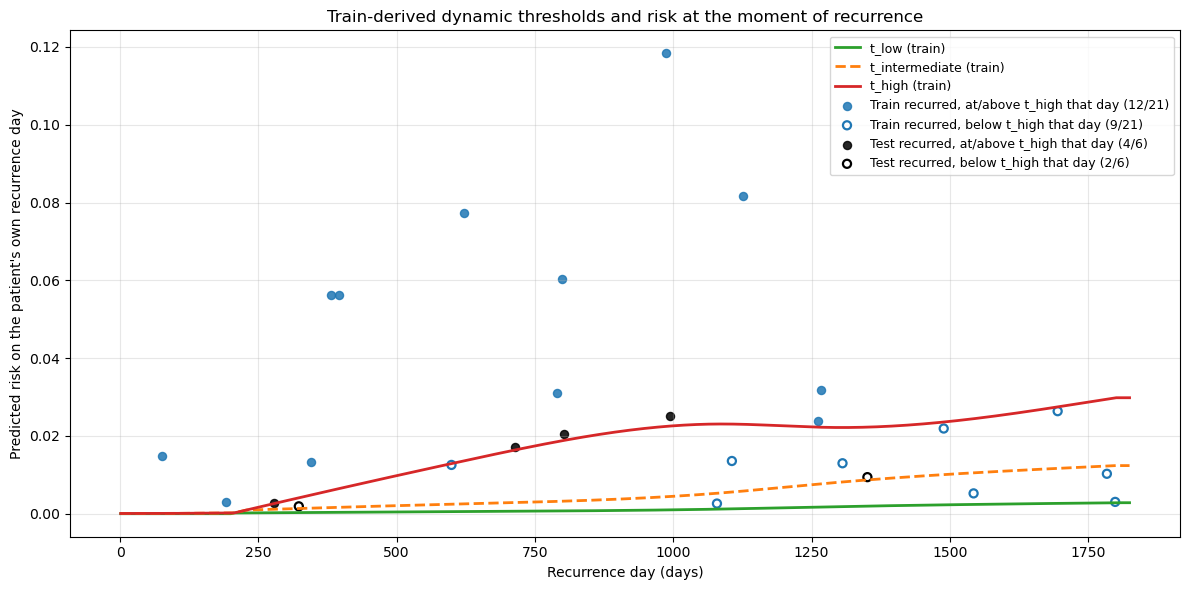

Same-day dynamic view (this figure):
  train: 12/21 recurrences were at/above t_high on their own day  |  21/21 had crossed t_high at some point by then
  test : 4/6 recurrences were at/above t_high on their own day  |  6/6 had crossed t_high at some point by then

Same-day flagging (this figure) vs fixed-horizon zone_4_high (zone tables).
These columns are expected to differ: risk(d|x) at the recurrence day is a
different quantity from risk(T|x) at the report horizon. The next cell shows
the fixed-horizon view and asserts it against the tables.


,time,events_by_T_train,same_day_flagged_train,fixed_horizon_zone4_train,events_by_T_test,same_day_flagged_test,fixed_horizon_zone4_test
0,365.0,3,3,2.0,2,1,0.0
1,730.0,7,6,5.0,3,2,1.0
2,1000.0,10,9,9.0,5,4,3.0
3,1095.0,11,9,9.0,5,4,3.0
4,1460.0,16,12,13.0,6,4,4.0
5,1825.0,21,12,16.0,6,4,5.0


In [16]:
# ============================================================================
# Dynamic thresholds and risk ON THE DAY OF RECURRENCE  (single-panel view)
# ============================================================================
# Each dot is one recurrence, scored on its OWN day: risk(d | x) plotted against
# the threshold curves in force on day d. This answers the dynamic-monitoring
# question "was this patient already flagged the day they recurred?".
#
# It is deliberately NOT the same quantity as the zone tables
# (group_metrics_train / group_metrics_test) and the *_events.png charts, which
# score everyone at a FIXED horizon T. Both are valid; they just answer
# different questions, and the reconciliation printed below (and the per-horizon
# figure in the next cell) shows exactly how the two sets of counts relate.
#
# Correctness fixes vs the earlier version of this cell:
#   * the red line drawn is the SAME t_high used for the above/below test, after
#     the monotonic sorted() guard that assign_dynamic_4zone_groups() applies
#     (previously the raw column was drawn, which can differ where the three
#     threshold curves cross);
#   * membership uses `>= t_high`, matching the zone function (was implicit);
#   * dots are split by above/below t_high so the plot cannot be eyeballed
#     into the wrong capture count;
#   * the axis labels and title state which quantity this is.

import numpy as np
import matplotlib.pyplot as plt

required_vars = [
    "fitted_threshold_model", "thresholds_df", "time_points",
    "x_train_scaled", "x_test_scaled", "y_train", "y_test", "_build_risk_matrix",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise NameError(f"Missing required variables in notebook context: {missing}")

# Risk over time from the TRAIN-fitted model
train_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_train_scaled, time_points)
test_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_test_scaled, time_points)

# Extract event/time from Surv structured arrays
event_train = y_train[y_train.dtype.names[0]].astype(bool)
time_train = y_train[y_train.dtype.names[1]].astype(float)
event_test = y_test[y_test.dtype.names[0]].astype(bool)
time_test = y_test[y_test.dtype.names[1]].astype(float)

grid = np.asarray(time_points, dtype=float)

# Threshold curves on the model grid, with the same monotonic guard the zoning
# function uses (it sorts the three thresholds at every time point).
thr = thresholds_df.sort_values("time")
if not np.allclose(thr["time"].to_numpy(dtype=float), grid):
    raise ValueError("thresholds_df['time'] does not match time_points; re-run the fit cell.")
t_low_curve, t_int_curve, t_high_curve = np.sort(
    np.vstack([
        thr["t_low"].to_numpy(dtype=float),
        thr["t_intermediate"].to_numpy(dtype=float),
        thr["t_high"].to_numpy(dtype=float),
    ]),
    axis=0,
)

# Keep only patients who recurred, and map each recurrence day onto the grid
idx_train_rec = np.where(event_train)[0]
idx_test_rec = np.where(event_test)[0]
t_train_rec = time_train[idx_train_rec]
t_test_rec = time_test[idx_test_rec]


def nearest_idx(times, grid_values):
    return np.abs(grid_values[:, None] - times[None, :]).argmin(axis=0)


j_train = nearest_idx(t_train_rec, grid)
j_test = nearest_idx(t_test_rec, grid)

# Risk attributed at the recurrence time, and the threshold in force that day
risk_train_rec = train_risk_matrix[idx_train_rec, j_train]
risk_test_rec = test_risk_matrix[idx_test_rec, j_test]
above_train = risk_train_rec >= t_high_curve[j_train]
above_test = risk_test_rec >= t_high_curve[j_test]

# Operationally the relevant question for a dynamic rule is whether the patient
# had EVER crossed t_high on or before the day they recurred, not only on that
# exact day. Cheap to compute, so report it alongside.
ever_train = np.array([
    bool(np.any(train_risk_matrix[i, : j + 1] >= t_high_curve[: j + 1]))
    for i, j in zip(idx_train_rec, j_train)
])
ever_test = np.array([
    bool(np.any(test_risk_matrix[i, : j + 1] >= t_high_curve[: j + 1]))
    for i, j in zip(idx_test_rec, j_test)
])

# ---------------------------------------------------------------- the figure
plt.figure(figsize=(12, 6))

# All three threshold curves learned on TRAIN
plt.plot(grid, t_low_curve, linewidth=2, color="tab:green", label="t_low (train)")
plt.plot(grid, t_int_curve, linewidth=2, linestyle="--", color="tab:orange",
         label="t_intermediate (train)")
plt.plot(grid, t_high_curve, linewidth=2, color="tab:red", label="t_high (train)")

# Recurrences: filled = at/above t_high that day, hollow = below it
plt.scatter(t_train_rec[above_train], risk_train_rec[above_train],
            s=34, alpha=0.85, color="tab:blue",
            label=f"Train recurred, at/above t_high that day ({int(above_train.sum())}/{len(t_train_rec)})")
plt.scatter(t_train_rec[~above_train], risk_train_rec[~above_train],
            s=34, facecolors="none", edgecolors="tab:blue", linewidths=1.6,
            label=f"Train recurred, below t_high that day ({int((~above_train).sum())}/{len(t_train_rec)})")
plt.scatter(t_test_rec[above_test], risk_test_rec[above_test],
            s=34, alpha=0.85, color="black",
            label=f"Test recurred, at/above t_high that day ({int(above_test.sum())}/{len(t_test_rec)})")
plt.scatter(t_test_rec[~above_test], risk_test_rec[~above_test],
            s=34, facecolors="none", edgecolors="black", linewidths=1.6,
            label=f"Test recurred, below t_high that day ({int((~above_test).sum())}/{len(t_test_rec)})")

plt.xlabel("Recurrence day (days)")
plt.ylabel("Predicted risk on the patient's own recurrence day")
plt.title("Train-derived dynamic thresholds and risk at the moment of recurrence")
plt.grid(alpha=0.3)
plt.legend(loc="best", frameon=True, fontsize=9)
plt.tight_layout()
plt.savefig("recurrence_risk_at_event_day.png", dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------- how this relates to the tables
print("Same-day dynamic view (this figure):")
print(f"  train: {int(above_train.sum())}/{len(t_train_rec)} recurrences were at/above t_high on their own day"
      f"  |  {int(ever_train.sum())}/{len(t_train_rec)} had crossed t_high at some point by then")
print(f"  test : {int(above_test.sum())}/{len(t_test_rec)} recurrences were at/above t_high on their own day"
      f"  |  {int(ever_test.sum())}/{len(t_test_rec)} had crossed t_high at some point by then")

metrics_train_ref = globals().get("group_metrics_train", None)
metrics_test_ref = globals().get("group_metrics_test", None)
horizons = np.asarray(globals().get("report_time_points", []), dtype=float)


def _zone4_events(metrics_df, horizon):
    if metrics_df is None:
        return np.nan
    sel = metrics_df.loc[
        (metrics_df["time"].astype(float) == float(horizon))
        & (metrics_df["risk_group"].astype(str) == "zone_4_high"),
        "events_in_group",
    ]
    return float(sel.iloc[0]) if len(sel) > 0 else np.nan


if len(horizons) > 0:
    rows = []
    for horizon in horizons:
        by_t_train = t_train_rec <= horizon
        by_t_test = t_test_rec <= horizon
        rows.append({
            "time": float(horizon),
            "events_by_T_train": int(by_t_train.sum()),
            "same_day_flagged_train": int(np.sum(above_train & by_t_train)),
            "fixed_horizon_zone4_train": _zone4_events(metrics_train_ref, horizon),
            "events_by_T_test": int(by_t_test.sum()),
            "same_day_flagged_test": int(np.sum(above_test & by_t_test)),
            "fixed_horizon_zone4_test": _zone4_events(metrics_test_ref, horizon),
        })
    same_day_vs_horizon = pd.DataFrame(rows)
    print(
        "\nSame-day flagging (this figure) vs fixed-horizon zone_4_high (zone tables).\n"
        "These columns are expected to differ: risk(d|x) at the recurrence day is a\n"
        "different quantity from risk(T|x) at the report horizon. The next cell shows\n"
        "the fixed-horizon view and asserts it against the tables."
    )
    display(same_day_vs_horizon)
    if metrics_train_ref is None or metrics_test_ref is None:
        print("Note: run the train/test zone-summary cells above to fill the fixed-horizon columns.")

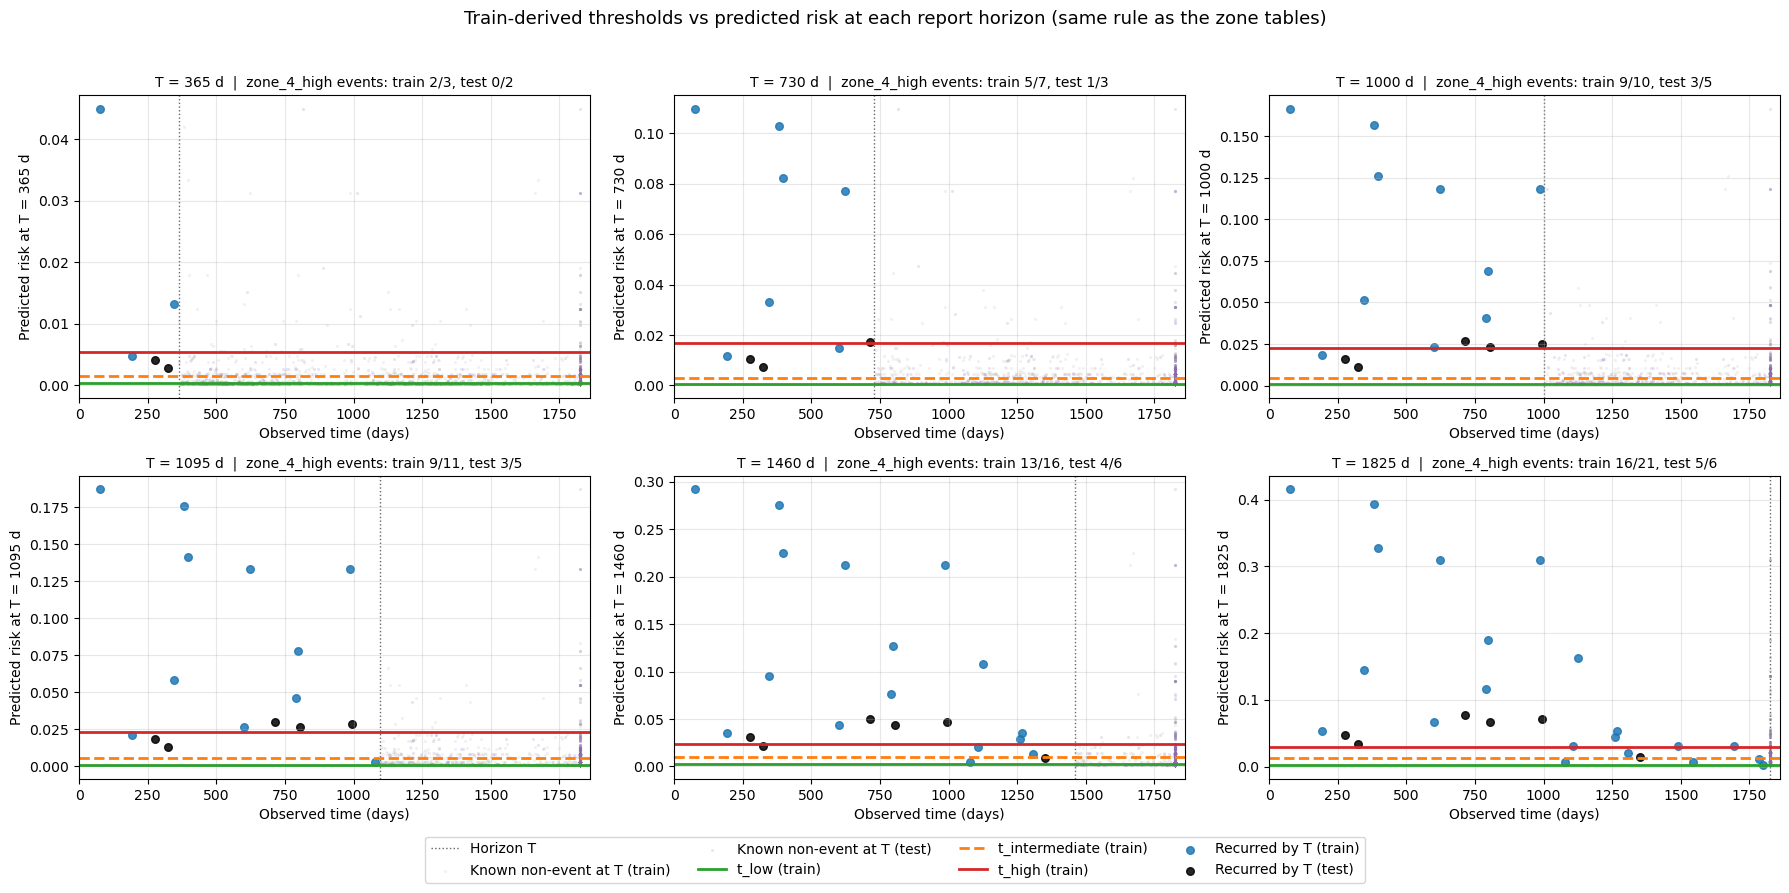

Figure vs zone-table agreement for zone_4_high:


,time,fig_events_zone4_train,tbl_events_zone4_train,fig_n_zone4_train,tbl_n_zone4_train,fig_events_zone4_test,tbl_events_zone4_test,fig_n_zone4_test,tbl_n_zone4_test,matches_tables
0,365.0,2,2.0,74,74.0,0,0.0,22,22.0,True
1,730.0,5,5.0,47,47.0,1,1.0,18,18.0,True
2,1000.0,9,9.0,52,52.0,3,3.0,19,19.0,True
3,1095.0,9,9.0,52,52.0,3,3.0,17,17.0,True
4,1460.0,13,13.0,85,85.0,4,4.0,31,31.0,True
5,1825.0,16,16.0,104,104.0,5,5.0,35,35.0,True


OK - every panel reproduces the zone_4_high counts in group_metrics_train/test.


In [17]:
# ============================================================================
# Reconciliation: recurrences vs thresholds at the FIXED report horizons
# ============================================================================
# This figure uses exactly the same scoring rule as the zone tables above
# (group_metrics_train / group_metrics_test) and the *_patients.png /
# *_events.png / *_rates.png charts, so the two can be read against each other:
#
#   * every patient is scored at the FIXED horizon T -> risk(T | x).
#     The previous version of this cell scored each patient at their OWN
#     recurrence day, which is a different quantity for every dot and is what
#     made it disagree with the zone tables (e.g. 3/3 dots above t_high at
#     day 365 in the old plot vs event_capture = 2/3 in the table).
#   * thresholds come from thresholds_df at that same T, drawn as horizontal
#     lines, with the same monotonic sorted() guard as
#     assign_dynamic_4zone_groups().
#   * the cohort shown at horizon T is the table's known-status set:
#       recurred by T  = event & time <= T           (the table's events)
#       non-event at T = time >= T and not recurred  (the table's non-events)
#
# Consequence: dots on/above the red line == zone_4_high counts in the tables.
# The check at the bottom asserts this numerically.

import numpy as np
import matplotlib.pyplot as plt

SHOW_NON_EVENTS = True  # grey dots = patients with known event-free status at T

required_vars = [
    "fitted_threshold_model", "thresholds_df", "time_points", "report_time_points",
    "x_train_scaled", "x_test_scaled", "y_train", "y_test", "_build_risk_matrix",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise NameError(f"Missing required variables in notebook context: {missing}")

# Risk over time from the TRAIN-fitted model
train_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_train_scaled, time_points)
test_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_test_scaled, time_points)

# Extract event/time from Surv structured arrays
event_train = y_train[y_train.dtype.names[0]].astype(bool)
time_train = y_train[y_train.dtype.names[1]].astype(float)
event_test = y_test[y_test.dtype.names[0]].astype(bool)
time_test = y_test[y_test.dtype.names[1]].astype(float)

grid = np.asarray(time_points, dtype=float)
horizons = np.asarray(report_time_points, dtype=float)


def _horizon_index(horizon):
    """Column of the risk matrix used for this horizon."""
    return int(np.argmin(np.abs(grid - float(horizon))))


def _thresholds_at(horizon):
    """(t_low, t_intermediate, t_high) at the horizon, monotonically sorted
    exactly as assign_dynamic_4zone_groups() does before zoning."""
    day = float(grid[_horizon_index(horizon)])
    row = thresholds_df.loc[thresholds_df["time"] == day]
    if row.empty:
        raise ValueError(f"Missing threshold row for time point {day}.")
    return tuple(sorted([
        float(row.iloc[0]["t_low"]),
        float(row.iloc[0]["t_intermediate"]),
        float(row.iloc[0]["t_high"]),
    ]))


def _table_value(metrics_df, horizon, column):
    """Pull the zone_4_high value of `column` at `horizon` from a group_metrics_* table."""
    if metrics_df is None:
        return np.nan
    sel = metrics_df.loc[
        (metrics_df["time"].astype(float) == float(horizon))
        & (metrics_df["risk_group"].astype(str) == "zone_4_high"),
        column,
    ]
    return float(sel.iloc[0]) if len(sel) > 0 else np.nan


metrics_train_ref = globals().get("group_metrics_train", None)
metrics_test_ref = globals().get("group_metrics_test", None)

n_panels = len(horizons)
n_cols = 3
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.0 * n_cols, 4.4 * n_rows))
axes = np.atleast_1d(axes).ravel()

check_rows = []
for ax, horizon in zip(axes, horizons):
    j = _horizon_index(horizon)
    t_low, t_intermediate, t_high = _thresholds_at(horizon)

    # Same cohort definition as summarize_group_metrics_* (known status at T)
    rec_train = event_train & (time_train <= horizon)
    rec_test = event_test & (time_test <= horizon)
    known_train = (time_train >= horizon) | rec_train
    known_test = (time_test >= horizon) | rec_test
    nonevent_train = known_train & ~rec_train
    nonevent_test = known_test & ~rec_test

    risk_train_rec = train_risk_matrix[rec_train, j]
    risk_test_rec = test_risk_matrix[rec_test, j]
    risk_train_non = train_risk_matrix[nonevent_train, j]
    risk_test_non = test_risk_matrix[nonevent_test, j]

    # Everyone left of the horizon line has recurred by T; everyone right of it is
    # still at risk at T. That is the known-status split the tables use.
    ax.axvline(float(horizon), color="0.4", linewidth=1, linestyle=":", zorder=0,
               label="Horizon T")

    if SHOW_NON_EVENTS:
        ax.scatter(time_train[nonevent_train], risk_train_non, s=5, alpha=0.10,
                   color="tab:gray", linewidths=0, label="Known non-event at T (train)")
        ax.scatter(time_test[nonevent_test], risk_test_non, s=5, alpha=0.18,
                   color="tab:purple", linewidths=0, label="Known non-event at T (test)")

    ax.axhline(t_low, linewidth=2, color="tab:green", label="t_low (train)")
    ax.axhline(t_intermediate, linewidth=2, linestyle="--", color="tab:orange",
               label="t_intermediate (train)")
    ax.axhline(t_high, linewidth=2, color="tab:red", label="t_high (train)")

    ax.scatter(time_train[rec_train], risk_train_rec, s=30, alpha=0.85,
               color="tab:blue", label="Recurred by T (train)")
    ax.scatter(time_test[rec_test], risk_test_rec, s=30, alpha=0.85,
               color="black", label="Recurred by T (test)")

    # zone_4_high membership is `risk >= t_high` (assign_dynamic_4zone_groups)
    ev_hi_train = int(np.sum(risk_train_rec >= t_high))
    ev_hi_test = int(np.sum(risk_test_rec >= t_high))
    n_hi_train = ev_hi_train + int(np.sum(risk_train_non >= t_high))
    n_hi_test = ev_hi_test + int(np.sum(risk_test_non >= t_high))

    ax.set_xlim(0.0, float(grid.max()) * 1.02)
    ax.set_xlabel("Observed time (days)")
    ax.set_ylabel(f"Predicted risk at T = {int(horizon)} d")
    ax.set_title(
        f"T = {int(horizon)} d  |  zone_4_high events: "
        f"train {ev_hi_train}/{int(rec_train.sum())}, test {ev_hi_test}/{int(rec_test.sum())}",
        fontsize=10,
    )
    ax.grid(alpha=0.3)

    check_rows.append({
        "time": float(horizon),
        "fig_events_zone4_train": ev_hi_train,
        "tbl_events_zone4_train": _table_value(metrics_train_ref, horizon, "events_in_group"),
        "fig_n_zone4_train": n_hi_train,
        "tbl_n_zone4_train": _table_value(metrics_train_ref, horizon, "n_group"),
        "fig_events_zone4_test": ev_hi_test,
        "tbl_events_zone4_test": _table_value(metrics_test_ref, horizon, "events_in_group"),
        "fig_n_zone4_test": n_hi_test,
        "tbl_n_zone4_test": _table_value(metrics_test_ref, horizon, "n_group"),
    })

for ax in axes[n_panels:]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=True,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle(
    "Train-derived thresholds vs predicted risk at each report horizon "
    "(same rule as the zone tables)",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.savefig("recurrence_risk_vs_thresholds_by_horizon.png", dpi=200, bbox_inches="tight")
plt.show()

# --- Consistency check against the zone tables ------------------------------
zone4_consistency = pd.DataFrame(check_rows)
compare_pairs = [
    ("fig_events_zone4_train", "tbl_events_zone4_train"),
    ("fig_n_zone4_train", "tbl_n_zone4_train"),
    ("fig_events_zone4_test", "tbl_events_zone4_test"),
    ("fig_n_zone4_test", "tbl_n_zone4_test"),
]
agree = np.ones(len(zone4_consistency), dtype=bool)
for fig_col, tbl_col in compare_pairs:
    known_pair = zone4_consistency[tbl_col].notna()
    agree &= (~known_pair) | (zone4_consistency[fig_col] == zone4_consistency[tbl_col])
zone4_consistency["matches_tables"] = agree

print("Figure vs zone-table agreement for zone_4_high:")
display(zone4_consistency)
if metrics_train_ref is None or metrics_test_ref is None:
    print("Note: run the train/test zone-summary cells above to enable the full check.")
elif bool(zone4_consistency["matches_tables"].all()):
    print("OK - every panel reproduces the zone_4_high counts in group_metrics_train/test.")
else:
    raise AssertionError(
        "Figure and zone tables disagree, so they were built from different model state. "
        "Re-run the fit cell and the zone-summary cells, then re-run this cell."
    )

In [18]:
# ============================================================================
# INTERVAL (non-cumulative) view of recurrences and zones
# ============================================================================
# The *_events.png charts from the earlier cell are CUMULATIVE: at horizon T
# they count every recurrence with time <= T, re-zoned at T. A recurrence on
# day 200 therefore appears in all six bars, each time under a different zone.
#
# Here each recurrence is counted ONCE, in the interval where it happened, so
# the bars are distributed across follow-up. Two classification rules are
# produced, because they answer different questions:
#
#   "landmark"  (recommended, the headline chart)
#       For interval (t1, t2]: take everyone still at risk at t1, zone them by
#       risk(t2 | x) vs thresholds(t2), then count the recurrences that fall
#       inside the interval. This is a decision you could actually make at the
#       start of the interval, and it comes with a denominator (who was at risk,
#       and how many of them were flagged for nothing).
#
#   "event_day" (the same-day view, for comparison)
#       Each recurrence is zoned using risk(d | x) vs thresholds(d) on its own
#       recurrence day d. CAVEAT: t_high is pinned to 0 before
#       high_curve_zero_start_time (150 d in the current fit), so any recurrence
#       in that window is "flagged" trivially -- every patient in the cohort
#       would be. Read the first interval of that chart with that in mind.
#
# Both rules use the same monotonic sorted() guard as assign_dynamic_4zone_groups.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sksurv.nonparametric import kaplan_meier_estimator

# Interval edges in days. Clean year boundaries; the 1000 d reporting horizon is
# deliberately not an edge (it would create a 95 d sliver next to 1095).
interval_edges = np.array([0.0, 365.0, 730.0, 1095.0, 1460.0, 1825.0], dtype=float)

zone_order = ["zone_1_low", "zone_2_mid_low", "zone_3_mid_high", "zone_4_high"]
zone_colors = {
    "zone_1_low": "#16A34A",
    "zone_2_mid_low": "#008080",
    "zone_3_mid_high": "#EAB308",
    "zone_4_high": "#E11D48",
}
BLACK = "#000000"
LIGHT_GRAY = "#E0E0E0"

required_vars = [
    "fitted_threshold_model", "thresholds_df", "time_points",
    "x_train_scaled", "x_test_scaled", "y_train", "y_test", "_build_risk_matrix",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise NameError(f"Missing required variables in notebook context: {missing}")

grid = np.asarray(time_points, dtype=float)

# Threshold curves on the model grid, with the zoning function's monotonic guard
_thr = thresholds_df.sort_values("time")
if not np.allclose(_thr["time"].to_numpy(dtype=float), grid):
    raise ValueError("thresholds_df['time'] does not match time_points; re-run the fit cell.")
t_low_curve, t_int_curve, t_high_curve = np.sort(
    np.vstack([
        _thr["t_low"].to_numpy(dtype=float),
        _thr["t_intermediate"].to_numpy(dtype=float),
        _thr["t_high"].to_numpy(dtype=float),
    ]),
    axis=0,
)


def _grid_idx(day):
    return int(np.argmin(np.abs(grid - float(day))))


def _zone_labels(risk_vec, t_low, t_int, t_high):
    """Same cut rule as assign_dynamic_4zone_groups; t_* may be scalars or arrays."""
    return np.where(
        risk_vec < t_low, zone_order[0],
        np.where(risk_vec < t_int, zone_order[1],
                 np.where(risk_vec < t_high, zone_order[2], zone_order[3])),
    )


def _km_interval_risk(event_vec, time_vec, t2):
    """KM probability of recurring by t2 within an at-risk subset (censoring-aware)."""
    if len(time_vec) == 0:
        return np.nan
    if int(np.sum(event_vec)) == 0:
        return 0.0
    km_t, km_s = kaplan_meier_estimator(np.asarray(event_vec, dtype=bool),
                                        np.asarray(time_vec, dtype=float))
    pos = int(np.searchsorted(km_t, float(t2), side="right")) - 1
    surv = float(km_s[pos]) if pos >= 0 else 1.0
    return float(1.0 - surv)


def build_interval_metrics(risk_matrix, event_vec, time_vec, dataset_label):
    # Same-day rule: zone every patient on their own observed day. Independent of
    # the interval, so compute it once.
    j_own = np.abs(grid[:, None] - time_vec[None, :]).argmin(axis=0)
    zone_event_day = _zone_labels(
        risk_matrix[np.arange(len(time_vec)), j_own],
        t_low_curve[j_own], t_int_curve[j_own], t_high_curve[j_own],
    )

    rows = []
    for k in range(len(interval_edges) - 1):
        t1 = float(interval_edges[k])
        t2 = float(interval_edges[k + 1])
        j2 = _grid_idx(t2)
        t_low, t_int, t_high = (t_low_curve[j2], t_int_curve[j2], t_high_curve[j2])

        # At risk at the start of the interval: followed to t1 and not yet recurred
        at_risk = (time_vec >= t1) & ~(event_vec & (time_vec <= t1))
        # Recurrences that happen inside the interval, counted exactly once
        in_interval = event_vec & (time_vec > t1) & (time_vec <= t2)

        zone_landmark = _zone_labels(risk_matrix[:, j2], t_low, t_int, t_high)

        for z in zone_order:
            in_zone = zone_landmark == z
            sub = at_risk & in_zone
            n_at_risk = int(np.sum(sub))
            n_events = int(np.sum(in_interval & in_zone))
            # Follow-up that ends inside the interval without a recurrence
            n_censored = int(np.sum(sub & ~event_vec & (time_vec < t2)))

            rows.append({
                "dataset": dataset_label,
                "interval": f"{t1 / 365.25:.0f}-{t2 / 365.25:.0f} y",
                "t_start": t1,
                "t_end": t2,
                "risk_group": z,
                "n_at_risk_t_start": n_at_risk,
                "n_events_in_interval": n_events,
                "n_censored_in_interval": n_censored,
                "rate_crude": (n_events / n_at_risk) if n_at_risk > 0 else np.nan,
                "rate_km": _km_interval_risk(event_vec[sub], time_vec[sub], t2),
                # same-day rule, events only (no denominator applies)
                "n_events_zone_at_event_day": int(np.sum(in_interval & (zone_event_day == z))),
                "t_low": float(t_low),
                "t_intermediate": float(t_int),
                "t_high": float(t_high),
            })
    out = pd.DataFrame(rows)
    out["risk_group"] = pd.Categorical(out["risk_group"], categories=zone_order, ordered=True)
    return out


train_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_train_scaled, time_points)
test_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_test_scaled, time_points)

event_train = y_train[y_train.dtype.names[0]].astype(bool)
time_train = y_train[y_train.dtype.names[1]].astype(float)
event_test = y_test[y_test.dtype.names[0]].astype(bool)
time_test = y_test[y_test.dtype.names[1]].astype(float)

interval_metrics = pd.concat(
    [
        build_interval_metrics(train_risk_matrix, event_train, time_train, "train"),
        build_interval_metrics(test_risk_matrix, event_test, time_test, "test"),
    ],
    ignore_index=True,
)

# ---------------------------------------------------------------- the charts
plt.rcParams.update({
    "font.family": "sans-serif",
    "text.color": BLACK,
    "axes.labelcolor": BLACK,
    "xtick.color": BLACK,
    "ytick.color": BLACK,
})


def _style(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=14, fontweight="bold", pad=18, loc="left")
    ax.set_xlabel(xlabel, fontsize=12, fontweight="bold", labelpad=10)
    ax.set_ylabel(ylabel, fontsize=12, fontweight="bold", labelpad=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)
    ax.tick_params(axis="both", which="major", labelsize=11, width=1.5, length=5)
    ax.grid(axis="y", color=LIGHT_GRAY, linestyle="-", linewidth=0.5, alpha=0.7)
    ax.set_axisbelow(True)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=11)


def plot_interval_events(dataset_name, rule, filename):
    """rule: 'landmark' (zone at interval start) or 'event_day' (zone on recurrence day)."""
    value_col = "n_events_in_interval" if rule == "landmark" else "n_events_zone_at_event_day"
    sub = interval_metrics.loc[interval_metrics["dataset"] == dataset_name]
    pivot = (sub.pivot_table(index="interval", columns="risk_group",
                             values=value_col, aggfunc="sum", observed=False)
             .reindex(columns=zone_order).fillna(0))
    order = sub.drop_duplicates("interval").sort_values("t_start")["interval"].tolist()
    pivot = pivot.reindex(order)

    fig, ax = plt.subplots(figsize=(8.5, 5.5), facecolor="white")
    ax.set_facecolor("white")
    x = np.arange(len(pivot.index))
    bottoms = np.zeros(len(x))
    for z in zone_order:
        vals = pivot[z].to_numpy(dtype=float)
        ax.bar(x, vals, bottom=bottoms, color=zone_colors[z], edgecolor="white",
               linewidth=1, width=0.6, label=z.replace("_", " ").title())
        bottoms += vals

    ax.set_xticks(x)
    if rule == "landmark":
        at_risk = (sub.groupby("interval", observed=False)["n_at_risk_t_start"].sum()
                   .reindex(order))
        ax.set_xticklabels([f"{lbl}\n(n={int(at_risk[lbl])})" for lbl in pivot.index],
                           fontweight="bold", fontsize=10)
        subtitle = "zone assigned at interval start; n = at risk entering the interval"
    else:
        ax.set_xticklabels(list(pivot.index), fontweight="bold")
        subtitle = "zone assigned on each patient's recurrence day"
    ax.set_ylim(0, max(3.0, float(bottoms.max()) * 1.25))
    _style(ax, f"{dataset_name.capitalize()} cohort: recurrences per interval\n({subtitle})",
           "Interval since diagnosis", "Recurrences in interval")
    plt.tight_layout()
    plt.savefig(filename, dpi=300, transparent=True, bbox_inches="tight")
    plt.close()


def plot_interval_rates(dataset_name, filename):
    sub = interval_metrics.loc[interval_metrics["dataset"] == dataset_name]
    order = sub.drop_duplicates("interval").sort_values("t_start")["interval"].tolist()
    pivot = (sub.pivot_table(index="interval", columns="risk_group", values="rate_km",
                             aggfunc="mean", observed=False)
             .reindex(columns=zone_order).reindex(order))

    fig, ax = plt.subplots(figsize=(8.5, 5.5), facecolor="white")
    ax.set_facecolor("white")
    x = np.arange(len(pivot.index))
    for z in zone_order:
        ax.plot(x, pivot[z].to_numpy(dtype=float) * 100.0, marker="o", markersize=8,
                linewidth=3, color=zone_colors[z], label=z.replace("_", " ").title())
    ax.set_xticks(x)
    ax.set_xticklabels(list(pivot.index), fontweight="bold")
    _style(ax, f"{dataset_name.capitalize()} cohort: recurrence risk within each interval\n"
               "(Kaplan-Meier, among those at risk and in that zone at interval start)",
           "Interval since diagnosis", "Recurrence risk in interval (%)")
    plt.tight_layout()
    plt.savefig(filename, dpi=300, transparent=True, bbox_inches="tight")
    plt.close()


for ds in ["train", "test"]:
    plot_interval_events(ds, "landmark", f"{ds}_interval_events_landmark.png")
    plot_interval_events(ds, "event_day", f"{ds}_interval_events_eventday.png")
    plot_interval_rates(ds, f"{ds}_interval_rates.png")

print("Wrote: {train,test}_interval_events_landmark.png, "
      "{train,test}_interval_events_eventday.png, {train,test}_interval_rates.png")

# Totals must equal the number of recurrences inside the 5-year window, once each
for ds, ev, tm in [("train", event_train, time_train), ("test", event_test, time_test)]:
    expected = int(np.sum(ev & (tm > float(interval_edges[0])) & (tm <= float(interval_edges[-1]))))
    sub = interval_metrics.loc[interval_metrics["dataset"] == ds]
    for col in ["n_events_in_interval", "n_events_zone_at_event_day"]:
        got = int(sub[col].sum())
        if got != expected:
            raise AssertionError(f"{ds}/{col}: intervals hold {got} recurrences, expected {expected}")
    outside = int(np.sum(ev & (tm > float(interval_edges[-1]))))
    print(f"{ds}: {expected} recurrences distributed across intervals (non-cumulative, counted once)"
          + (f" | WARNING: {outside} recurrence(s) after day {interval_edges[-1]:.0f} are outside the "
             "interval grid; extend interval_edges to include them." if outside else ""))

display(
    interval_metrics[[
        "dataset", "interval", "risk_group", "n_at_risk_t_start", "n_events_in_interval",
        "n_censored_in_interval", "rate_crude", "rate_km", "n_events_zone_at_event_day",
        "t_high",
    ]]
)

Wrote: {train,test}_interval_events_landmark.png, {train,test}_interval_events_eventday.png, {train,test}_interval_rates.png
train: 21 recurrences distributed across intervals (non-cumulative, counted once)
test: 6 recurrences distributed across intervals (non-cumulative, counted once)


,dataset,interval,risk_group,n_at_risk_t_start,n_events_in_interval,n_censored_in_interval,rate_crude,rate_km,n_events_zone_at_event_day,t_high
0,train,0-1 y,zone_1_low,1184,0,69,0.000000,0.000000,0,0.005457
1,train,0-1 y,zone_2_mid_low,853,0,49,0.000000,0.000000,0,0.005457
2,train,0-1 y,zone_3_mid_high,469,1,19,0.002132,0.002146,0,0.005457
3,train,0-1 y,zone_4_high,76,2,2,0.026316,0.026676,3,0.005457
4,train,1-2 y,zone_1_low,108,0,22,0.000000,0.000000,0,0.016853
5,train,1-2 y,zone_2_mid_low,1719,0,395,0.000000,0.000000,0,0.016853
6,train,1-2 y,zone_3_mid_high,561,1,109,0.001783,0.002037,1,0.016853
7,train,1-2 y,zone_4_high,52,3,7,0.057692,0.061560,3,0.016853
8,train,2-3 y,zone_1_low,737,0,84,0.000000,0.000000,0,0.023061
9,train,2-3 y,zone_2_mid_low,673,1,114,0.001486,0.001773,1,0.023061


In [19]:
import pickle
from pathlib import Path
import numpy as np
import pandas as pd

from functions.threshold import _build_risk_matrix

# GUARD: this cell REPLACES fitted_threshold_model, thresholds_df, the train/test
# split and the scaled matrices built by cells 2-13. Running it mid-notebook is
# what makes the figures above it (zone tables, threshold curves, recurrence
# scatter) and the figures below it (ROC, DCA) come from two different fits with
# possibly different split indices. Leave this False to keep the in-notebook fit;
# set it to True only when you deliberately want the archived bundle instead.
LOAD_BUNDLE_OVERRIDE = False

# Load the precomputed bundle saved in this folder
BUNDLE_PATH = Path("coxnet_model_bundle.pkl")

if not LOAD_BUNDLE_OVERRIDE:
    print(
        "Bundle load SKIPPED (LOAD_BUNDLE_OVERRIDE=False): keeping the in-notebook fit "
        "so every figure in this notebook comes from the same model, thresholds and split."
    )
    print(f"Set LOAD_BUNDLE_OVERRIDE=True to load {BUNDLE_PATH} instead, then re-run the cells above.")
else:
    if not BUNDLE_PATH.exists():
        raise FileNotFoundError(f"Bundle not found: {BUNDLE_PATH.resolve()}")

    with open(BUNDLE_PATH, "rb") as f:
        bundle = pickle.load(f)

    if not isinstance(bundle, dict):
        raise TypeError(f"Expected dict in bundle, got {type(bundle)}")

    # Restore the main variables used by downstream cells
    core_vars = [
        "best_params_for_calibration",
        "scaler",
        "x_train_scaled",
        "x_test_scaled",
        "y_train",
        "y_test",
        "coef_df",
        "nonzero_coef_df",
        "time_points",
        "report_time_points",
        "thresholds_df",
        "thresholds_report",
        "threshold_result",
        "fitted_threshold_model",
        "cox_model",
        "intermediate_threshold_method",
    ]
    for name in core_vars:
        if name in bundle:
            globals()[name] = bundle[name]

    # Handle model naming differences across saved bundles
    if "fitted_threshold_model" not in globals() and "cox_model" in globals():
        fitted_threshold_model = cox_model
    if "cox_model" not in globals() and "fitted_threshold_model" in globals():
        cox_model = fitted_threshold_model

    # Rebuild threshold tables if only threshold_result was stored
    if "thresholds_df" not in globals() and "threshold_result" in globals() and hasattr(threshold_result, "thresholds"):
        thresholds_df = threshold_result.thresholds
    if "thresholds_report" not in globals() and "thresholds_df" in globals() and "report_time_points" in globals():
        report_mask = thresholds_df["time"].isin(np.asarray(report_time_points, dtype=float))
        keep_cols = [
            c for c in ["time", "t_low", "t_intermediate", "t_high", "event_prevalence", "roc_n_used", "roc_computable"]
            if c in thresholds_df.columns
        ]
        thresholds_report = thresholds_df.loc[report_mask, keep_cols].copy()

    # Helpful check for the next cells
    required_next = [
        "fitted_threshold_model",
        "x_train_scaled",
        "x_test_scaled",
        "y_train",
        "y_test",
        "time_points",
    ]
    missing_next = [v for v in required_next if v not in globals()]

    print(f"Loaded bundle: {BUNDLE_PATH.resolve()}")
    print(f"Bundle keys ({len(bundle)}): {sorted(bundle.keys())}")
    if missing_next:
        print(f"Missing for next cells: {missing_next}")
    else:
        print("All required variables for the next threshold cells are available.")
    print(
        "WARNING: model/thresholds/split replaced by the bundle. Every figure and table "
        "above this cell must be re-run before it can be compared with anything below it."
    )

Bundle load SKIPPED (LOAD_BUNDLE_OVERRIDE=False): keeping the in-notebook fit so every figure in this notebook comes from the same model, thresholds and split.
Set LOAD_BUNDLE_OVERRIDE=True to load coxnet_model_bundle.pkl instead, then re-run the cells above.


Time used: 1500.0 days
Known n: 1140 | Events by t: 17
prevalence_method=kaplan_meier | event_prevalence_t=0.009505
utility_weighting=ipcw
m_high=10.420817
Chosen threshold c*=0.104232
Max U(c)=0.322863 at ROC point (FPR=0.008014, TPR=0.406378)


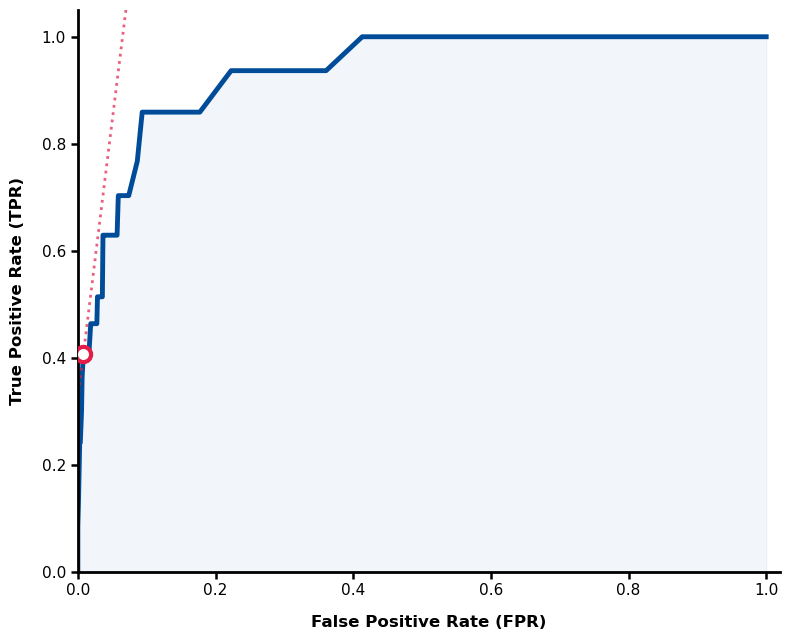

Columns in displayed array: [threshold, FPR, TPR, U(c)]


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from sksurv.nonparametric import kaplan_meier_estimator

# ============================================================
# SETTINGS YOU CAN CHANGE
# ============================================================
timepoint = 1500.0  # days (example: 365, 730, 1095, 1460, 1825)
prevalence_method = "kaplan_meier"   # "kaplan_meier" or "empirical_known"
utility_weighting = "ipcw"           # "unweighted" or "ipcw"
ipcw_min_censoring_survival = 1e-6

# "HIGH" costs for THIS ROC illustration only.
# These are deliberately roc_-prefixed: the un-prefixed names are the globals set in
# the settings cell (FN cost 66.7) and consumed by every fit_dynamic_thresholds call.
# Overwriting them here silently changed t_high on any later refit.
roc_high_false_positive_cost = 1.0
roc_high_false_negative_cost = 10.0
roc_high_true_positive_cost = 0.0
roc_high_true_negative_cost = 0.0

# ============================================================
# REQUIRES EXISTING NOTEBOOK VARIABLES
# fitted_threshold_model, x_train_scaled, y_train, time_points, _build_risk_matrix
# ============================================================
required = [
    "fitted_threshold_model", "x_train_scaled", "y_train", "time_points", "_build_risk_matrix"
]
missing = [v for v in required if v not in globals()]
if missing:
    raise NameError(f"Missing variables: {missing}")

# ------------------------------------------------------------
# Helpers aligned with functions.threshold logic
# ------------------------------------------------------------
def _step_survival_at_times(step_times, step_survival, query_times):
    step_times = np.asarray(step_times, dtype=float)
    step_survival = np.asarray(step_survival, dtype=float)
    query_times = np.asarray(query_times, dtype=float)
    out = np.ones_like(query_times, dtype=float)
    idx = np.searchsorted(step_times, query_times, side="right") - 1
    valid = idx >= 0
    out[valid] = step_survival[idx[valid]]
    return np.clip(out, 0.0, 1.0)

def _km_survival_at_times(events, times, q_times):
    km_t, km_s = kaplan_meier_estimator(
        np.asarray(events, dtype=bool),
        np.asarray(times, dtype=float),
    )
    return _step_survival_at_times(km_t, km_s, np.asarray(q_times, dtype=float))

def _compute_m_from_costs(event_prevalence, c_fp, c_fn, c_tp=0.0, c_tn=0.0):
    # m = P(non-event)/P(event) * (C_FP - C_TN)/(C_FN - C_TP)
    p = float(event_prevalence)
    p = max(1e-6, min(1.0 - 1e-6, p))
    num = float(c_fp) - float(c_tn)
    den = float(c_fn) - float(c_tp)
    if den <= 0:
        raise ValueError("(C_FN - C_TP) must be > 0.")
    if num < 0:
        raise ValueError("(C_FP - C_TN) must be >= 0.")
    return ((1.0 - p) / p) * (num / den)

# ------------------------------------------------------------
# Extract train event/time and risk at the chosen timepoint
# ------------------------------------------------------------
event_field = y_train.dtype.names[0]
time_field = y_train.dtype.names[1]
event_train = y_train[event_field].astype(bool)
time_train = y_train[time_field].astype(float)

risk_train = _build_risk_matrix(fitted_threshold_model, x_train_scaled, time_points)

t_grid = np.asarray(time_points, dtype=float)
time_idx = int(np.argmin(np.abs(t_grid - float(timepoint))))
t_used = float(t_grid[time_idx])

scores_t = risk_train[:, time_idx]

# Known status at horizon t (same rule as fit_dynamic_thresholds)
known_mask = (time_train >= t_used) | (event_train & (time_train <= t_used))
if known_mask.sum() < 3:
    raise ValueError(f"Too few known samples at t={t_used:.1f} (n={known_mask.sum()}).")

y_bin = (event_train[known_mask] & (time_train[known_mask] <= t_used)).astype(int)
x_scores = scores_t[known_mask]

if y_bin.min() == y_bin.max():
    raise ValueError(f"ROC not computable at t={t_used:.1f}: only one class present.")

# ------------------------------------------------------------
# Prevalence and m(t) exactly in the spirit of fit_dynamic_thresholds
# ------------------------------------------------------------
if prevalence_method == "kaplan_meier":
    event_prevalence_t = float(1.0 - _km_survival_at_times(event_train, time_train, np.array([t_used]))[0])
elif prevalence_method == "empirical_known":
    event_prevalence_t = float(np.mean(y_bin))
else:
    raise ValueError("prevalence_method must be 'kaplan_meier' or 'empirical_known'.")

m_high = _compute_m_from_costs(
    event_prevalence=event_prevalence_t,
    c_fp=roc_high_false_positive_cost,
    c_fn=roc_high_false_negative_cost,
    c_tp=roc_high_true_positive_cost,
    c_tn=roc_high_true_negative_cost,
)

# ------------------------------------------------------------
# Optional IPCW weighting (same construction style as fit_dynamic_thresholds)
# ------------------------------------------------------------
sample_weights_full = None
if utility_weighting == "ipcw":
    censor_event = ~event_train
    censor_t, censor_s = kaplan_meier_estimator(censor_event, time_train)

    G_at_sample = _step_survival_at_times(censor_t, censor_s, time_train)
    G_at_t = float(_step_survival_at_times(censor_t, censor_s, np.array([t_used]))[0])

    G_at_sample = np.clip(G_at_sample, ipcw_min_censoring_survival, 1.0)
    G_at_t = max(ipcw_min_censoring_survival, min(1.0, G_at_t))

    sample_weights_full = np.zeros_like(time_train, dtype=float)
    case_mask_t = event_train & (time_train <= t_used)
    control_mask_t = time_train >= t_used
    sample_weights_full[case_mask_t] = 1.0 / G_at_sample[case_mask_t]
    sample_weights_full[control_mask_t] = 1.0 / G_at_t

    w = sample_weights_full[known_mask]
    w_pos = float(np.sum(w[y_bin == 1]))
    w_neg = float(np.sum(w[y_bin == 0]))
    if w_pos <= 0.0 or w_neg <= 0.0:
        raise ValueError("IPCW weights degenerate at this timepoint (no positive weight in one class).")
elif utility_weighting == "unweighted":
    w = None
else:
    raise ValueError("utility_weighting must be 'unweighted' or 'ipcw'.")

# ------------------------------------------------------------
# ROC + utility U(c) = TPR(c) - m*FPR(c), choose c* maximizing U(c)
# ------------------------------------------------------------
fpr, tpr, thr = roc_curve(y_bin, x_scores, sample_weight=w, drop_intermediate=False)
U = tpr - (m_high * fpr)

best_idx = int(np.argmax(U))
c_star = float(np.clip(thr[best_idx], 0.0, 1.0))
u_star = float(U[best_idx])
fpr_star = float(fpr[best_idx])
tpr_star = float(tpr[best_idx])

print(f"Time used: {t_used:.1f} days")
print(f"Known n: {known_mask.sum()} | Events by t: {int(np.sum(y_bin))}")
print(f"prevalence_method={prevalence_method} | event_prevalence_t={event_prevalence_t:.6f}")
print(f"utility_weighting={utility_weighting}")
print(f"m_high={m_high:.6f}")
print(f"Chosen threshold c*={c_star:.6f}")
print(f"Max U(c)={u_star:.6f} at ROC point (FPR={fpr_star:.6f}, TPR={tpr_star:.6f})")

# ------------------------------------------------------------
# ------------------------------------------------------------
# Plot ROC and mark the max-U(c) point (PRESENTATION READY)
# ------------------------------------------------------------

# 1. Theme Colors & Settings (Dark Scheme for White Background)
DARK_BLUE = '#004C99' 
CRIMSON = '#E11D48'     
BLACK = '#000000'       
LIGHT_GRAY = '#E0E0E0'  

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
})

# 2. Setup Figure
fig, ax = plt.subplots(figsize=(8, 6.5), facecolor='white')
ax.set_facecolor('white')

# 3. Plotting the ROC Curve
ax.plot(fpr, tpr, color=DARK_BLUE, linewidth=3.5, label='ROC Curve')

# Add subtle shading under the ROC curve 
ax.fill_between(fpr, tpr, color=DARK_BLUE, alpha=0.05)

# 4. Iso-utility line and Optimal Point
# Calculate the line extending from the optimal point with slope m_high
x_line = np.array([-0.1, 1.1]) # Extend slightly beyond the plot
y_line = tpr_star + m_high * (x_line - fpr_star)

# Plot iso-utility line
ax.plot(x_line, y_line, linestyle=':', color=CRIMSON, linewidth=2, alpha=0.7, 
        label=f'Iso-utility slope (m={m_high:.2f})')

# Plot the optimal point
ax.scatter([fpr_star], [tpr_star], color='white', edgecolor=CRIMSON, s=120, linewidth=3, zorder=5)

# Modern floating annotation box for the optimal threshold
bbox_props = dict(boxstyle="round,pad=0.6", fc='#F8FAFC', ec=CRIMSON, alpha=0.9, lw=1.5)

# Calculate positioning so text doesn't fall off the graph
text_x = fpr_star + 0.05 if fpr_star < 0.6 else fpr_star - 0.4
text_y = tpr_star - 0.15 if tpr_star > 0.3 else tpr_star + 0.15

# 5. Clean Formatting
ax.set_xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold', labelpad=12)
ax.set_ylabel('True Positive Rate (TPR)', fontsize=12, fontweight='bold', labelpad=12)

# Spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_color(BLACK)
ax.spines['bottom'].set_color(BLACK)

# Ticks
ax.tick_params(axis='both', which='major', labelsize=11, width=1.8, length=5, colors=BLACK)

# Set limits
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.05)

# Grid
ax.set_axisbelow(True)


plt.tight_layout()

# Export with Transparency (Ensures it drops cleanly onto any white/light slide)
plt.savefig('roc_utility_hq.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()
print("Columns in displayed array: [threshold, FPR, TPR, U(c)]")

## Decision curve analysis (5-year horizon)

Rough cut at **clinical net benefit** — does using the model's risk score to decide who
gets intervention beat the two default strategies, treat everyone or treat no one, at a
given risk threshold? Net benefit is read against those two: **model** uses predicted
5-year recurrence risk to decide, **treat all** intervenes on everyone, **treat none** on
nobody, and whichever curve sits highest at a threshold is the better call there.

DCA evaluated at horizon day: 1825
Evaluable patients at horizon: 229
Observed event prevalence at horizon: 0.0262
Model has higher net benefit than Treat-All and Treat-None for thresholds from 0.010 to 0.075.


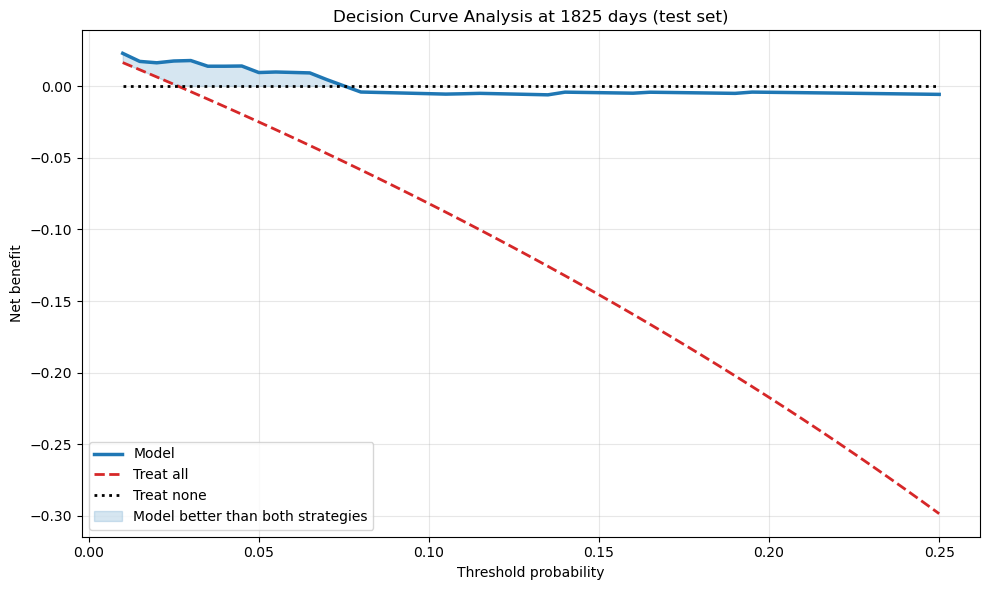

,threshold_probability,net_benefit_model,net_benefit_treat_all,net_benefit_treat_none
0,0.010,0.022804,0.016365,0.0
1,0.015,0.017179,0.011371,0.0
2,0.020,0.016220,0.006327,0.0
3,0.025,0.017467,0.001232,0.0
4,0.030,0.017782,-0.003917,0.0
5,0.035,0.013824,-0.009118,0.0
6,0.040,0.013828,-0.014374,0.0
7,0.045,0.013969,-0.019685,0.0
8,0.050,0.009423,-0.025052,0.0
9,0.055,0.009796,-0.030475,0.0


In [21]:
# Decision Curve Analysis at 5 years (1825 days)
# Uses test-set predictions from the already fitted threshold model.

horizon_day = 1825.0

# Build test risk matrix if it does not already exist in memory
if 'test_risk_matrix' not in globals():
    test_risk_matrix = _build_risk_matrix(fitted_threshold_model, x_test_scaled, time_points)

# Survival target fields
event_field_test = y_test.dtype.names[0]
time_field_test = y_test.dtype.names[1]
event_test = y_test[event_field_test].astype(bool)
time_test = y_test[time_field_test].astype(float)

# Choose horizon index from the model time grid
time_points_arr = np.asarray(time_points, dtype=float)
horizon_idx = int(np.argmin(np.abs(time_points_arr - horizon_day)))
selected_horizon = float(time_points_arr[horizon_idx])

# Predicted risk at the 5-year horizon
pred_risk_h = test_risk_matrix[:, horizon_idx].astype(float)

# Use only patients with known 5-year status under this horizoning rule
known_mask = (time_test >= selected_horizon) | (event_test & (time_test <= selected_horizon))
y_true_h = (event_test[known_mask] & (time_test[known_mask] <= selected_horizon)).astype(int)
pred_known = pred_risk_h[known_mask]

n_eval = int(known_mask.sum())
prevalence = float(y_true_h.mean()) if n_eval > 0 else np.nan

# Threshold range usually discussed for adjuvant decisions
pt_grid = np.arange(0.01, 0.251, 0.005)

rows = []
for pt in pt_grid:
    pred_positive = (pred_known >= pt).astype(int)

    tp = np.sum((pred_positive == 1) & (y_true_h == 1))
    fp = np.sum((pred_positive == 1) & (y_true_h == 0))

    odds = pt / (1.0 - pt)
    nb_model = (tp / n_eval) - (fp / n_eval) * odds
    nb_all = prevalence - (1.0 - prevalence) * odds
    nb_none = 0.0

    rows.append({
        'threshold_probability': float(pt),
        'net_benefit_model': float(nb_model),
        'net_benefit_treat_all': float(nb_all),
        'net_benefit_treat_none': float(nb_none),
    })

dca_df = pd.DataFrame(rows)

# Find threshold range where model is best among standard alternatives
better_than_all = dca_df['net_benefit_model'] > dca_df['net_benefit_treat_all']
better_than_none = dca_df['net_benefit_model'] > dca_df['net_benefit_treat_none']
clinically_useful_mask = better_than_all & better_than_none

print(f'DCA evaluated at horizon day: {selected_horizon:.0f}')
print(f'Evaluable patients at horizon: {n_eval}')
print(f'Observed event prevalence at horizon: {prevalence:.4f}')

if clinically_useful_mask.any():
    useful_thresholds = dca_df.loc[clinically_useful_mask, 'threshold_probability']
    print(
        'Model has higher net benefit than Treat-All and Treat-None for thresholds from '
        f"{useful_thresholds.min():.3f} to {useful_thresholds.max():.3f}."
    )
else:
    print('No threshold in the selected range where model outperforms both Treat-All and Treat-None.')

# Plot for clinicians
plt.figure(figsize=(10, 6))
plt.plot(
    dca_df['threshold_probability'],
    dca_df['net_benefit_model'],
    label='Model',
    linewidth=2.5,
    color='tab:blue',
)
plt.plot(
    dca_df['threshold_probability'],
    dca_df['net_benefit_treat_all'],
    label='Treat all',
    linestyle='--',
    linewidth=2,
    color='tab:red',
)
plt.plot(
    dca_df['threshold_probability'],
    dca_df['net_benefit_treat_none'],
    label='Treat none',
    linestyle=':',
    linewidth=2,
    color='black',
)

# Highlight the clinically useful region where model dominates both comparators
if clinically_useful_mask.any():
    plt.fill_between(
        dca_df['threshold_probability'],
        dca_df['net_benefit_model'],
        np.maximum(dca_df['net_benefit_treat_all'], dca_df['net_benefit_treat_none']),
        where=clinically_useful_mask,
        alpha=0.18,
        color='tab:blue',
        interpolate=True,
        label='Model better than both strategies',
    )

plt.xlabel('Threshold probability')
plt.ylabel('Net benefit')
plt.title(f'Decision Curve Analysis at {int(selected_horizon)} days (test set)')
plt.grid(alpha=0.3)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

display(dca_df.head(10))